# P02: Clasificación de la informalidad laboral en México con la ENOE 2T-2026.

---
Nombres:\
**Claudio Alejo Encarnación Martínez (750597)** \
**Alan Jesús Hernández Soto (752714)** 

Carrera: **Ingeniería Financiera** \
Materia: **Laboratorio de Aprendizaje Estadístico** \
Tipo de Trabajo: **Proyecto**

---

## 1. Objetivos

### 1.1 Objetivo general

Construir y comparar tres modelos de clasificación supervisada (regresión logística con regularización, máquina de vectores de soporte con kernel RBF y perceptrón multicapa), cuyos hiperparámetros se optimizan mediante optimización bayesiana con procesos gaussianos, para clasificar si una persona ocupada en México tiene un empleo informal a partir de los microdatos de la ENOE del segundo trimestre de 2026. El trabajo final permite estimar informalidad laboral y desarrollar perfiles en zonas o municipios para un posible desarrollo de nuevas políticas, programas o aciones focalizadas.

### 1.2 Objetivos específicos

1. Depurar y transformar los microdatos sociodemográficos de la ENOE 2T-2026 (tabla SDEM) para construir tres conjuntos de datos de distinta escala geográfica (Área Metropolitana de Guadalajara con 5 municipios, Jalisco y nacional), documentando y justificando cada decisión de limpieza.
2. Realizar un análisis exploratorio que identifique las variables más asociadas con la informalidad, así como problemas potenciales en los datos (redundancia, baja varianza y variables que funcionan casi como la variable objetivo).
3. Diseñar un pipeline de preprocesamiento reproducible (imputación, escalamiento y codificación OneHot) que se ajuste dentro de cada fold.
4. Optimizar los hiperparámetros de cada modelo con Optuna, maximizando el ROC-AUC promedio de una validación cruzada estratificada de 5 folds.
5. Comparar los modelos optimizados mediante la media y la desviación estándar del ROC-AUC en una validación cruzada de 10 folds, y verificar su desempeño en un conjunto de prueba independiente.
6. Evaluar si el desempeño y el modelo ganador se mantienen al pasar de la AMG a Jalisco y al conjunto nacional.
7. Interpretar los coeficientes de la regresión logística para identificar qué características se asocian con mayor o menor probabilidad de informalidad.

## 2. Marco teórico

### 2.1 Regresión logística

La regresión logística es un modelo para respuestas cualitativas. En lugar de predecir directamente la clase, modela la probabilidad de que una observación pertenezca a la clase positiva ($y=1$, empleo informal) aplicando la función sigmoide a una combinación lineal de los predictores:

$$ p(\mathbf{x}) = P(y=1 \mid \mathbf{x}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p)}} $$

Esto equivale a un modelo lineal en el *logit* (logaritmo de los momios):

$$ \ln\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p $$

Por eso $e^{\beta_j}$ se interpreta como una **razón de momios**: cuánto se multiplican los momios de ser informal cuando $x_j$ aumenta una unidad y lo demás se mantiene fijo.

Los coeficientes se estiman por máxima verosimilitud, lo que equivale a minimizar la función de costo de entropía cruzada (*log-loss*):

$$ J(\boldsymbol{\beta}) = -\sum_{i=1}^{n} \left[ y_i \ln(\hat{p}_i) + (1-y_i)\ln(1-\hat{p}_i) \right] $$

Esta función es **convexa**: cualquier mínimo local es global, así que el resultado no depende de la inicialización.

**Regularización.** Para controlar el sobreajuste y la colinealidad se agrega una penalización sobre los coeficientes. La forma general que usa `scikit-learn` (red elástica) es:

$$ \min_{\boldsymbol{\beta}} \; C \sum_{i=1}^{n} \ell(y_i, \hat{p}_i) + \frac{1-\rho}{2}\lVert\boldsymbol{\beta}\rVert_2^2 + \rho\lVert\boldsymbol{\beta}\rVert_1 $$

- $C$ es el **inverso** de la fuerza de regularización: un $C$ pequeño penaliza más y un $C$ grande se acerca a la regresión sin penalizar.
- $\rho$ (`l1_ratio`) mezcla las penalizaciones: $\rho=0$ es Ridge (L2, encoge todos los coeficientes), $\rho=1$ es Lasso (L1, puede volver exactamente cero algunos coeficientes, es decir, hace selección de variables) y $0<\rho<1$ es red elástica.
- **Nota:** a partir de `scikit-learn` 1.8 el argumento `penalty` está en desuso. La penalización se define solo con `C` y `l1_ratio`. La red elástica requiere el *solver* `saga`.

### 2.2 Máquinas de vectores de soporte (SVM)

Una SVM busca el hiperplano que separa las clases con el **margen máximo**, es decir, la mayor distancia posible entre el hiperplano y los puntos más cercanos de cada clase (los vectores de soporte):

$$ f(\mathbf{x}) = \mathbf{w}^T \varphi(\mathbf{x}) + b $$

donde $\varphi$ lleva cada observación a un espacio de características (un espacio de Hilbert). Como en datos reales las clases se traslapan, se usa el **margen suave**, que permite errores mediante variables de holgura $\xi_i$ (con $y_i \in \{-1, 1\}$):

$$
\begin{split}
\min_{\mathbf{w}, b, \xi} \; & \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_{i=1}^{n}\xi_i \\
\text{s.a. } & y_i\left[\mathbf{w}^T\varphi(\mathbf{x}_i) + b\right] \geq 1 - \xi_i, \quad \xi_i \geq 0
\end{split}
$$

El hiperparámetro $C$ controla el balance entre un margen amplio y pocos errores de entrenamiento. Un $C$ grande castiga mucho los errores (frontera más ajustada, riesgo de sobreajuste) y un $C$ pequeño tolera más errores (frontera más suave).

Al resolver el problema dual, la función de decisión queda en términos de los vectores de soporte ($\alpha_i > 0$):

$$ f(\mathbf{x}) = \sum_{i=1}^{n} \alpha_i y_i K(\mathbf{x}_i, \mathbf{x}) + b $$

La SVM no entrega probabilidades directamente, pero el valor de $f(\mathbf{x})$ (distancia con signo al hiperplano, `decision_function`) basta para ordenar las observaciones y calcular el ROC-AUC. Su costo de entrenamiento crece aproximadamente entre $O(n^2)$ y $O(n^3)$ con el número de observaciones, lo que importa mucho en el conjunto nacional.

### 2.3 Kernels

El **truco del kernel** evita calcular $\varphi(\mathbf{x})$ de forma explícita: basta con una función que devuelva el producto interno en el espacio transformado,

$$ K(\mathbf{x}, \mathbf{x}') = \langle \varphi(\mathbf{x}), \varphi(\mathbf{x}') \rangle $$

Así se pueden obtener fronteras no lineales en el espacio original y conservar un problema de optimización convexo. Los kernels más comunes:

| Kernel | Fórmula | Comentario |
|---|---|---|
| Lineal | $\mathbf{x}^T\mathbf{x}'$ | Equivale a una frontera lineal |
| Polinomial | $(\gamma\,\mathbf{x}^T\mathbf{x}' + r)^d$ | Interacciones hasta grado $d$ |
| RBF (gaussiano) | $\exp\left(-\gamma\lVert\mathbf{x}-\mathbf{x}'\rVert^2\right)$ | Espacio de dimensión infinita; el más usado |
| Sigmoide | $\tanh(\gamma\,\mathbf{x}^T\mathbf{x}' + r)$ | Inspirado en redes neuronales |

En el kernel RBF, $\gamma$ controla el alcance de cada punto de entrenamiento. Con $\gamma$ grande, cada punto influye solo muy cerca de sí mismo y la frontera se vuelve muy irregular (sobreajuste). Con $\gamma$ pequeño, la influencia es amplia y la frontera tiende a ser casi lineal. $C$ y $\gamma$ interactúan, por lo que deben optimizarse juntos.

Los kernels también son la pieza central de los **procesos gaussianos** (sección 2.7): ahí el kernel mide qué tan parecidos esperamos que sean los valores de la función objetivo en dos configuraciones de hiperparámetros cercanas.

### 2.4 Redes neuronales: perceptrón multicapa (MLP)

Un perceptrón multicapa es una composición de regresiones logísticas (o, en general, de neuronas) organizadas en capas. Cada neurona calcula una combinación lineal de sus entradas y le aplica una función de activación no lineal $g$:

$$ \mathbf{h}^{(l)} = g\left(\mathbf{W}^{(l)}\mathbf{h}^{(l-1)} + \mathbf{b}^{(l)}\right), \qquad \mathbf{h}^{(0)} = \mathbf{x} $$

En clasificación binaria la capa de salida usa una sigmoide para producir $\hat{p}(\mathbf{x})$. En este trabajo las capas ocultas usan ReLU, $g(z) = \max(0, z)$.

La red se entrena minimizando la entropía cruzada más una penalización L2 sobre los pesos, controlada por $\alpha$:

$$ J(\mathbf{W}) = -\sum_{i=1}^{n}\left[y_i\ln\hat{p}_i + (1-y_i)\ln(1-\hat{p}_i)\right] + \frac{\alpha}{2}\lVert\mathbf{W}\rVert_2^2 $$

Los gradientes se calculan con *backpropagation* y los pesos se actualizan con el optimizador Adam, cuyo tamaño de paso inicial es `learning_rate_init`. A diferencia de la regresión logística, **la función de costo no es convexa**: hay mínimos locales y puntos silla, y el resultado depende de la inicialización (por eso se fija `random_state`). Para no entrenar de más se usa `early_stopping`, que separa una fracción del entrenamiento como validación y detiene el ajuste cuando la métrica deja de mejorar.

Hiperparámetros principales: número de capas ocultas y de neuronas por capa (`hidden_layer_sizes`), regularización (`alpha`) y tasa de aprendizaje (`learning_rate_init`).

### 2.5 Métricas para clasificación

Toda clasificación binaria produce cuatro casos, que se resumen en la **matriz de confusión**:

| | Predicho: formal (0) | Predicho: informal (1) |
|---|---|---|
| **Real: formal (0)** | Verdadero negativo (TN) | Falso positivo (FP) |
| **Real: informal (1)** | Falso negativo (FN) | Verdadero positivo (TP) |

A partir de ella:

$$ \text{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN} \qquad \text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall (TPR)} = \frac{TP}{TP+FN} $$

$$ \text{Specificity} = \frac{TN}{TN+FP} \qquad \text{FPR} = \frac{FP}{FP+TN} = 1 - \text{Specificity} \qquad F_1 = 2\,\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}} $$

Todas estas métricas dependen del **umbral** con el que una probabilidad se convierte en clase (normalmente 0.5).

La **curva ROC** grafica el TPR contra el FPR para todos los umbrales posibles, y el **AUC** es el área bajo esa curva. El AUC equivale a la probabilidad de que el modelo asigne un puntaje mayor a un informal elegido al azar que a un formal elegido al azar: 0.5 es azar y 1 es separación perfecta.

**Métrica elegida: ROC-AUC.** Las razones:

1. No depende del umbral, así que compara la capacidad de discriminar de modelos que producen puntajes en escalas distintas (probabilidades en la logística y el MLP, distancias en la SVM).
2. Es robusta ante el desbalance moderado de las clases (alrededor de 39 % de informales en la AMG y 52 % en el nacional).
3. En este problema no hay una asimetría clara de costos entre falsos positivos y falsos negativos. Accuracy, precision, recall y $F_1$ se reportan como complemento.

**Validación cruzada *k-folds*.** Los datos de entrenamiento se dividen en $k$ partes; se entrena con $k-1$ y se evalúa en la restante, rotando $k$ veces. Se usa la versión **estratificada** (cada *fold* conserva la proporción de clases). El desempeño se resume con

$$ \overline{AUC} = \frac{1}{k}\sum_{j=1}^{k} AUC_j \qquad\qquad s = \sqrt{\frac{1}{k}\sum_{j=1}^{k}\left(AUC_j - \overline{AUC}\right)^2} $$

La media indica el desempeño esperado y la desviación, qué tan estable es ante cambios en los datos de entrenamiento.

### 2.6 Hiperparámetros

Un **parámetro** se estima automáticamente a partir de los datos durante el entrenamiento (por ejemplo, los coeficientes $\beta$ de la regresión logística o los pesos $\mathbf{W}$ de la red). Un **hiperparámetro** se fija *antes* de entrenar y controla cómo aprende el modelo (por ejemplo, $C$, $\gamma$ o el número de neuronas). Un mal valor de hiperparámetros puede producir subajuste o sobreajuste aunque el modelo sea el adecuado.

| Modelo | Hiperparámetros optimizados | Qué controlan |
|---|---|---|
| Regresión logística | $C$, `l1_ratio` | Fuerza y tipo de regularización |
| SVM RBF | $C$, $\gamma$ | Penalización de errores y alcance del kernel |
| MLP | número de capas, neuronas por capa, $\alpha$, `learning_rate_init` | Capacidad de la red, regularización y velocidad de aprendizaje |

Métodos de búsqueda:

- **Búsqueda en rejilla (`GridSearchCV`)**: prueba todas las combinaciones de una lista de valores. Es exhaustiva, pero su costo crece exponencialmente con el número de hiperparámetros.
- **Búsqueda aleatoria (`RandomizedSearchCV`)**: muestrea combinaciones al azar. Es más eficiente que la rejilla, pero no aprende de los resultados anteriores (en la analogía de la batalla naval, sigue tirando al azar aunque ya haya atinado a un barco).
- **Optimización bayesiana**: usa los resultados anteriores para decidir qué combinación probar después.

### 2.7 Optimización bayesiana

Elegir hiperparámetros es optimizar una función $f(\boldsymbol{\lambda})$, en este caso el ROC-AUC promedio de la validación cruzada para la configuración $\boldsymbol{\lambda}$. Esta función es **costosa** de evaluar (cada evaluación entrena el modelo $k$ veces), **no tiene gradiente** y puede tener ruido. La optimización bayesiana aplica el teorema de Bayes,

$$ \text{posterior} = \frac{(\text{verosimilitud})(\text{anterior})}{\text{evidencia}}, $$

para actualizar lo que creemos sobre $f$ cada vez que observamos una nueva evaluación.

**1. Modelo sustituto: proceso gaussiano (GP).** Se supone que $f$ es una realización de un proceso gaussiano, $f \sim \mathcal{GP}\big(m(\boldsymbol{\lambda}), k(\boldsymbol{\lambda}, \boldsymbol{\lambda}')\big)$: cualquier conjunto finito de valores de $f$ tiene distribución normal multivariada, y el kernel $k$ (por ejemplo, RBF o Matérn) dice qué tan correlacionados están dos puntos según su cercanía. Con las observaciones $\mathcal{D}_t = \{(\boldsymbol{\lambda}_i, y_i)\}_{i=1}^{t}$, la distribución posterior en un punto nuevo $\boldsymbol{\lambda}_*$ es normal, con

$$ \mu_t(\boldsymbol{\lambda}_*) = \mathbf{k}_*^T(\mathbf{K} + \sigma_n^2\mathbf{I})^{-1}\mathbf{y} $$

$$ \sigma_t^2(\boldsymbol{\lambda}_*) = k(\boldsymbol{\lambda}_*, \boldsymbol{\lambda}_*) - \mathbf{k}_*^T(\mathbf{K} + \sigma_n^2\mathbf{I})^{-1}\mathbf{k}_* $$

donde $\mathbf{K}$ es la matriz de kernel entre los puntos observados y $\mathbf{k}_*$ el vector de kernel entre $\boldsymbol{\lambda}_*$ y los observados. La media $\mu_t$ es la predicción y $\sigma_t$ la incertidumbre (las bandas $\pm 2\sigma$ que se graficaron en clase).

**2. Función de adquisición.** Decide dónde evaluar después, balanceando **explotación** (ir donde $\mu_t$ es alta) y **exploración** (ir donde $\sigma_t$ es grande). Dos ejemplos:

- *Upper Confidence Bound*: $\text{UCB}(\boldsymbol{\lambda}) = \mu_t(\boldsymbol{\lambda}) + \kappa\,\sigma_t(\boldsymbol{\lambda})$. Es el criterio de "maximización".
- *Expected Improvement*: $\text{EI}(\boldsymbol{\lambda}) = \mathbb{E}\left[\max(0, f(\boldsymbol{\lambda}) - f^+)\right] = (\mu_t - f^+)\,\Phi(Z) + \sigma_t\,\phi(Z)$, con $Z = \frac{\mu_t - f^+}{\sigma_t}$ y $f^+$ el mejor valor observado.

**3. Algoritmo.**
1. Evaluar $f$ en unos cuantos puntos iniciales aleatorios.
2. Ajustar el GP a todas las evaluaciones disponibles.
3. Maximizar la función de adquisición para elegir $\boldsymbol{\lambda}_{t+1}$.
4. Evaluar $f(\boldsymbol{\lambda}_{t+1})$ (entrenar con validación cruzada) y agregarlo a $\mathcal{D}$.
5. Repetir desde 2 hasta agotar el presupuesto de evaluaciones.

**Implementación con Optuna.** Optuna organiza la búsqueda en cuatro piezas:

- **Función objetivo**: recibe un `trial`, le pide valores de hiperparámetros (`trial.suggest_float`, `trial.suggest_int`), entrena y devuelve la métrica.
- **`trial`**: una evaluación concreta de la función objetivo.
- **`study`**: el conjunto de *trials* y la dirección de optimización (`maximize`).
- **`sampler`**: el algoritmo que propone los hiperparámetros del siguiente *trial*.

El *sampler* por defecto de Optuna es TPE (*Tree-structured Parzen Estimator*), que también es bayesiano pero **no** usa procesos gaussianos: modela densidades separadas para las configuraciones buenas y las malas. Para este proyecto, se usa `optuna.samplers.GPSampler`. Este *sampler* ajusta un GP (kernel Matérn 5/2) a los *trials* anteriores y elige el siguiente punto maximizando una versión de la mejora esperada. Los primeros `n_startup_trials` se eligen al azar, igual que el paso 1 del algoritmo. `GPSampler` necesita que esté instalado PyTorch.

### 2.8 Tema elegido: la informalidad laboral

De acuerdo con el marco de la Organización Internacional del Trabajo (OIT), que adopta el INEGI, el **empleo informal** abarca a las personas ocupadas que trabajan sin la protección institucional que da una relación laboral formal. Incluye dos grandes grupos:

1. Quienes trabajan en el **sector informal**: unidades económicas de los hogares que operan sin registros contables ni constitución como empresa.
2. Quienes, fuera del sector informal, trabajan **sin acceso a la seguridad social** por su relación laboral: trabajadores subordinados sin seguridad social en empresas, gobierno o instituciones; trabajo doméstico remunerado sin seguridad social; agricultura de autosubsistencia; y trabajadores no remunerados.

La **Encuesta Nacional de Ocupación y Empleo (ENOE)** del INEGI es la fuente oficial de estas cifras en México. En la tabla sociodemográfica (SDEM), la variable `emp_ppal` clasifica a la población ocupada según la condición de informalidad de su empleo principal (1 = empleo informal, 2 = empleo formal; 0 = no aplica para quienes no están ocupados).

La informalidad importa porque se asocia con falta de seguridad social y prestaciones, menor estabilidad del ingreso y menor productividad. La literatura asocia la informalidad con:

- menor escolaridad;
- edades extremas (jóvenes y adultos mayores);
- sectores como el agropecuario, la construcción y el comercio;
- localidades pequeñas o rurales;
- jornadas parciales o muy irregulares.

En este proyecto la informalidad se trata como un problema de **clasificación binaria**. El objetivo no es explicar las causas de la informalidad, sino aplicar y comparar las herramientas de aprendizaje estadístico vistas en el curso sobre un problema real. Todos los resultados se refieren únicamente a la muestra del segundo trimestre de 2026.

## 3. Análisis del dataset

### 3.1 ¿De dónde viene?

Los datos provienen de los microdatos de la **Encuesta Nacional de Ocupación y Empleo (ENOE)** del INEGI, **segundo trimestre de 2026** (abril-junio), archivo `conjunto_de_datos_sdem_enoe_2026_2t.csv` de la tabla **SDEM** (sociodemográfico).

- Es una encuesta en hogares con diseño probabilístico (estratificado y por conglomerados) y representatividad nacional, estatal y para las principales ciudades.
- Cada vivienda permanece cinco trimestres en la muestra (panel rotatorio), así que en cada trimestre se renueva una quinta parte.
- El archivo original tiene **417,128 registros y 115 columnas** y viene codificado en `latin-1`.

### 3.2 ¿Qué contiene?

Una fila por cada persona residente de las viviendas entrevistadas. Incluye identificadores geográficos y de la vivienda, características sociodemográficas (sexo, edad, escolaridad, estado conyugal) y variables laborales precodificadas por el INEGI (condición de actividad, posición en la ocupación, sector, horas trabajadas, ingreso, informalidad). Solo se usan las siguientes:

| Variable | Descripción | Tipo / codificación |
|---|---|---|
| `emp_ppal` | Condición de informalidad del empleo principal | 1 informal, 2 formal, 0 no aplica → **variable objetivo** |
| `r_def` | Resultado definitivo de la entrevista | 0 = entrevista completa |
| `clase2` | Clasificación de la población (PEA/PNEA) | 1 = población ocupada |
| `eda` | Edad en años | Numérica (99 = no especificado) |
| `anios_esc` | Años de escolaridad | Numérica (99 = no especificado) |
| `hrsocup` | Horas trabajadas en la semana | Numérica (0 a 168) |
| `ingocup` | Ingreso mensual por trabajo (pesos) | Numérica (0 incluye "no recibe" y "no especificado") |
| `ing7c` | Ingreso en rangos de salario mínimo | 1-5 rangos, 6 no recibe ingresos, 7 no especificado (solo para el EDA) |
| `pos_ocu` | Posición en la ocupación | Solo para verificar la codificación de `emp_ppal` |
| `sex` | Sexo | 1 hombre, 2 mujer |
| `e_con` | Estado conyugal | 1-6 (9 = no especificado) |
| `niv_ins` | Nivel de instrucción | 1 primaria incompleta, 2 primaria completa, 3 secundaria completa, 4 media superior y superior, 5 no especificado |
| `cs_p12` | ¿Sabe leer y escribir un recado? | 1 sí, 2 no (9 = no sabe) |
| `cs_p17` | ¿Asiste actualmente a la escuela? | 1 sí, 2 no (9 = no sabe) |
| `t_loc_tri` | Tamaño de localidad | 1 = 100 mil y más ... 4 = menos de 2,500 habitantes |
| `ur` | Ámbito | 1 urbano, 2 rural |
| `zona` | Zona salarial | 1, 2 |
| `rama` | Sector de actividad (7 categorías) | 1 construcción, 2 manufactura, 3 comercio, 4 servicios, 5 otros, 6 agropecuario, 7 no especificado |
| `scian` | Sector SCIAN (más fino que `rama`) | ~21 categorías |
| `dur9c` | Duración de la jornada (9 categorías) | 1 ausentes con vínculo, 2 menos de 15 h, ..., 8 más de 56 h, 9 no especificado |
| `cve_ent`, `cve_mun` | Entidad y municipio | Claves geográficas |
| `fac_tri` | Factor de expansión trimestral | Número de personas que representa cada registro |


### 3.3 ¿Qué información dan las muestras?

Cada muestra describe a una persona entrevistada en el trimestre. Para la población ocupada se describen las características de su **empleo principal**: sector, jornada, ingreso y si es formal o informal. Cada registro representa a `fac_tri` personas de la población, pero en el modelado se trabaja con la **muestra sin ponderar** (ver la discusión de `fac_tri` en la sección 3.5).

### 3.4 ¿Qué se quiere analizar?

Si, a partir de características sociodemográficas y laborales básicas (sin usar las variables con las que el INEGI construye la informalidad, como el acceso a seguridad social o el tipo de unidad económica), es posible **clasificar si el empleo principal de una persona ocupada es informal**, y qué tan bien lo hacen tres modelos de complejidad creciente con hiperparámetros optimizados.

El análisis se hace en tres escalas:

| Conjunto | Contenido |
|---|---|
| **AMG5** | Guadalajara, Zapopan, Tlaquepaque, Tonalá y Tlajomulco |
| **Jalisco** | Toda la entidad |
| **Nacional** | Las 32 entidades |

### 3.5 ¿Qué variables se tienen que transformar y qué transformaciones se van a usar?

| Variable(s) | Problema | Transformación |
|---|---|---|
| `emp_ppal` | Tres códigos (0, 1, 2) | Filtrar a ocupados con 1 o 2 y crear `y = 1` si es informal |
| Todas | El CSV trae espacios y vacíos | Leer como texto, quitar espacios y convertir a número (`errors="coerce"`) |
| `anios_esc`, `e_con`, `cs_p12`, `cs_p17` | Códigos de "no especificado" (99, 9) | Reemplazar por `NaN` y eliminar esas filas (son menos del 0.4 %) |
| `ingocup` | Muy sesgada y con muchos ceros (no recibe o no especificó) | `log_ing = ln(1 + ingocup)` más la bandera `ing_cero` |
| `hrsocup` | Ceros (ausentes temporales) | Bandera `hrs_cero` |
| `eda`, `anios_esc`, `hrsocup`, `log_ing` | Escalas distintas | `StandardScaler` (necesario para la SVM y el MLP y para que la penalización trate igual a todos los coeficientes) |
| `sex`, `cs_p12`, `cs_p17`, `ur` | Codificadas 1/2 | `OneHotEncoder(drop="if_binary")`, que deja una sola columna 0/1 |
| `e_con`, `niv_ins`, `t_loc_tri`, `rama`/`scian`, `dur9c` | Nominales u ordinales con códigos arbitrarios | `OneHotEncoder` con `min_frequency=0.01` (agrupa categorías raras) |
| `cve_mun` / `cve_ent` | La clave de municipio se repite entre estados | Variable `geo`: municipio en AMG5 y Jalisco, entidad en el nacional |
| `fac_tri` | Ponderador muestral, no una característica de la persona | **No entra como predictora.** Por eso los resultados describen la muestra, no la población |
| `cve_ent`, `zona` | Constantes en AMG5 y Jalisco | Se quitan (`cve_ent` regresa como `geo` en el nacional) |
| `ingocup` | Redundante con `log_ing` e `ing_cero` | Se quita del modelo |
| `rama` / `scian` | Miden lo mismo (sector) con distinto detalle | Se decide con datos mediante una ablación (sección 5.3): se usa **solo una** de las dos para no duplicar información |

**No se eliminan duplicados.** En microdatos de encuesta, dos filas iguales en las variables elegidas no son registros repetidos sino dos personas distintas con el mismo perfil. Eliminarlas quitaría justo los perfiles más comunes, alteraría el balance de clases y reduciría una muestra que en la AMG ya es pequeña.

### 3.6 ¿Qué resultado se podría encontrar al realizar una regresión?

Con base en el marco teórico se espera que:

- la probabilidad de informalidad **disminuya** con la escolaridad y con el ingreso reportado;
- **aumente** en el sector agropecuario, en la construcción, en jornadas de menos de 15 horas, en localidades pequeñas o rurales y entre quienes no reciben ingresos;
- la edad tenga una relación en forma de **U** (más informalidad en jóvenes y adultos mayores), que la regresión logística lineal no puede capturar sin un término cuadrático;
- los modelos alcancen un ROC-AUC claramente superior a 0.5, pero lejos de 1, porque la informalidad depende de factores que no están en las variables usadas (seguridad social, tipo de empleador);
- los modelos no lineales (SVM RBF y MLP) mejoren poco o moderadamente a la regresión logística, ya que gran parte de la señal está en variables categóricas que la logística aprovecha bien.

## Código

### 3.7 Importación de librerías

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report, RocCurveDisplay)
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel

import optuna


### 3.8 Parámetros generales del experimento

Todos los parámetros de costo computacional están en esta celda.

- **`MODO_PRUEBA = True`** corre todo el notebook con muy pocas iteraciones y muestras pequeñas. Sirve para comprobar en pocos minutos que no hay errores antes de lanzar la corrida completa.
- **Corrida completa:** con `MODO_PRUEBA = False`, AMG5 y Jalisco tardan minutos. El conjunto nacional puede tardar varias horas; para él hay un tope de tiempo por estudio y los *trials* se guardan en un archivo SQLite para poder reanudar si se interrumpe.

In [ ]:
SEMILLA = 67

N_TRIALS  = 30      # evaluaciones por modelo en la optimización bayesiana
N_STARTUP = 5       # de esas, cuántas son aleatorias antes de que el GP empiece a proponer
K_OPT     = 5       # folds de la validación cruzada DENTRO de la optimización
K_FINAL   = 10      # folds de la validación cruzada para comparar los modelos ya optimizados
TEST_SIZE = 0.20    # proporción del conjunto de prueba

# Para el dataset nacional
N_SVC_NACIONAL   = 30000      # submuestra estratificada para la SVM (su costo crece entre n^2 y n^3)
MUESTRA_NACIONAL = None       # None = usar todo el nacional; un número = submuestra para pruebas
TIMEOUT_NACIONAL = 5 * 3600   # tope (segundos) por estudio de Optuna en el nacional

MODO_PRUEBA = True 

if MODO_PRUEBA:
    N_TRIALS, N_STARTUP, K_OPT, K_FINAL = 4, 2, 3, 3
    N_SVC_NACIONAL, MUESTRA_NACIONAL = 3000, 15000

np.random.seed(SEMILLA)
print("Modo prueba:", MODO_PRUEBA, "| trials por modelo:", N_TRIALS)

Modo prueba: True | trials por modelo: 4


### 3.9 Limpieza de datos (desde el CSV original del INEGI)

La limpieza se hace una sola vez sobre el archivo nacional y al final se separan los tres conjuntos, para que los tres compartan exactamente las mismas reglas.

Se definen las columnas que se leen del archivo original y su papel en el análisis.

In [84]:
RUTA_SDEM = "/Users/claudioalejoencarnacionmartinez/Documents/SEMESTRE OTOÑO 2026/LAB APRENDIZAJE ESTADÍSTICO/LABORATORIO-DE-APRENDIZAJE-ESTAD-STICO/SEGUNDO PARCIAL/PROYECTO_02/conjunto_de_datos_sdem_enoe_2026_2t.csv"
CARPETA_SALIDA = "PROYECTO_02"
GUARDAR_CSV = False

ID_COLS     = ["cve_ent", "cve_mun", "fac_tri"]
FILTRO_COLS = ["r_def", "clase2", "emp_ppal", "ingocup"]

NUMERICAS_CRUDAS = ["eda", "anios_esc", "hrsocup"]
NUMERICAS   = ["eda", "anios_esc", "hrsocup", "log_ing"]
BINARIAS    = ["hrs_cero", "ing_cero"]
CATEGORICAS = ["sex", "e_con", "niv_ins", "cs_p12", "cs_p17",
               "t_loc_tri", "zona", "ur", "rama", "scian", "dur9c"]
PREDICTORAS = NUMERICAS + BINARIAS + CATEGORICAS

# columnas que de verdad existen en el CSV original 
COLS_CRUDAS = ID_COLS + FILTRO_COLS + NUMERICAS_CRUDAS + CATEGORICAS

CODIGO_INFORMAL = 1          
MUNICIPIOS_AMG5 = [39, 120, 98, 101, 97]   # GDL, Zapopan, Tlaquepaque, Tonalá, Tlajomulco
ELIMINAR_NULOS  = True       # False -> deja los NaN para imputarlos dentro del Pipeline

# Códigos de "no especificado" -> NaN
INVALIDOS = {
    "anios_esc": [99],
    "e_con":     [9],
    "cs_p12":    [9],
    "cs_p17":    [9],
}
# niv_ins = 5, rama = 7 y dur9c = 9 también son "no especificado", pero se dejan como una categoría más

**Carga y tipos.** El archivo trae celdas con espacios en blanco, así que se lee todo como texto, se quitan los espacios y luego se convierte a número. Lo que no es numérico (celdas vacías) queda como `NaN`.

In [85]:
n_cols_original = pd.read_csv(RUTA_SDEM, nrows=0, encoding="latin-1").shape[1]

usar = set(COLS_CRUDAS)
df_raw = pd.read_csv(RUTA_SDEM, dtype=str, encoding="latin-1",
                  usecols=lambda c: c.strip().lower() in usar)
df_raw.columns = df_raw.columns.str.strip().str.lower()
df_raw = df_raw.apply(lambda s: s.str.strip())
print(f"Columnas en el archivo original: {n_cols_original}")
print(f"Datos originales (columnas seleccionadas): {df_raw.shape}")


for c in COLS_CRUDAS:
    df_raw[c] = pd.to_numeric(df_raw[c], errors="coerce")

df_raw.head()

Columnas en el archivo original: 115
Datos originales (columnas seleccionadas): (417128, 21)


,r_def,cve_mun,t_loc_tri,cve_ent,sex,eda,cs_p12,cs_p17,e_con,ur,...,fac_tri,clase2,rama,dur9c,niv_ins,anios_esc,hrsocup,ingocup,scian,emp_ppal
0,0,7.0,1,9,1.0,64.0,1.0,2.0,5.0,1,...,1204,4,0,0,2,6,0,0,0,0
1,0,11.0,1,9,1.0,28.0,1.0,2.0,6.0,1,...,1323,1,4,6,4,16,40,0,12,2
2,0,14.0,1,9,1.0,68.0,1.0,2.0,6.0,1,...,1896,4,0,0,4,12,0,0,0,0
3,0,2.0,1,9,2.0,43.0,1.0,2.0,6.0,1,...,1005,1,4,4,4,16,29,0,12,1
4,0,7.0,1,9,1.0,27.0,1.0,2.0,6.0,1,...,485,2,0,0,4,16,0,0,0,0


Filtros estructurales.

- `r_def = 0`: solo entrevistas completas. Esta es la **base 100 %**.
- `clase2 = 1`: solo población ocupada, porque la informalidad solo se define para quien trabaja.
- Edad de 15 años o más (la ENOE define la población en edad de trabajar a partir de 15), excluyendo el código 99.
- `emp_ppal` en {1, 2}: etiqueta válida.

In [86]:
# Base 100% = entrevistas completas
len_base = len(df_raw)
df = df_raw[df_raw["r_def"] == 0]
resumen = [("Total en la base (todas las personas)", len(df_raw)),
           ("Entrevista completa (r_def = 0)  [BASE 100%]", len(df))]

df = df[df["clase2"] == 1]
resumen.append(("Población ocupada (clase2 = 1)", len(df)))
df = df[(df["eda"] >= 15) & (df["eda"] != 99)]
resumen.append(("Edad >= 15 (excluye 99 = no especif.)", len(df)))
df = df[df["emp_ppal"].isin([1, 2])]
resumen.append(("Etiqueta válida (emp_ppal en {1, 2})", len(df)))
df = df.copy()
pd.DataFrame(resumen)

,0,1
0,Total en la base (todas las personas),417128
1,Entrevista completa (r_def = 0) [BASE 100%],416393
2,Población ocupada (clase2 = 1),190325
3,Edad >= 15 (excluye 99 = no especif.),189353
4,"Etiqueta válida (emp_ppal en {1, 2})",189353


**Códigos especiales, variables derivadas y nulos.**

- Los códigos de "no especificado" se reemplazan por `NaN` y esas filas se eliminan. Son muy pocas, así que el sesgo es despreciable.
- Antes de revisar los nulos se crean las variables derivadas del ingreso y las horas:
  - `log_ing = ln(1 + ingocup)`: el `+1` evita $\ln(0)$.
  - `ing_cero = 1` si `ingocup = 0`.
  - `hrs_cero = 1` si `hrsocup = 0`.

In [87]:
#LIMPIEZA DE CÓDIGOS ESPECIALES
#El INEGI usa 99 o 9 para "no especificado".
print("Filas con código de 'no especificado':")
print("anios_esc = 99:", (df["anios_esc"] == 99).sum())
print("e_con = 9:     ", (df["e_con"] == 9).sum())
print("cs_p12 = 9:    ", (df["cs_p12"] == 9).sum())
print("cs_p17 = 9:    ", (df["cs_p17"] == 9).sum())

#Se reemplazan por NaN para eliminarlos después junto con los demás nulos
df["anios_esc"] = df["anios_esc"].replace(99, np.nan)
df["e_con"] = df["e_con"].replace(9, np.nan)
df["cs_p12"] = df["cs_p12"].replace(9, np.nan)
df["cs_p17"] = df["cs_p17"].replace(9, np.nan)

# Revisión: ya no deben quedar esos códigos, ahora aparecen como nulos
print("\nNulos después de reemplazar:")
print(df[["anios_esc", "e_con", "cs_p12", "cs_p17"]].isna().sum())

# Variables derivadas del ingreso y las horas
df["hrs_cero"] = (df["hrsocup"] == 0).astype(int)   # 1 si trabajó 0 horas
df["ing_cero"] = (df["ingocup"] == 0).astype(int)   # 1 si el ingreso es 0
df["log_ing"] = np.log(df["ingocup"] + 1)           # +1 para evitar log(0)

# NULOS
print("Nulos por predictora:")
print(df[PREDICTORAS].isna().sum())

antes = len(df)
df = df.dropna(subset=PREDICTORAS)
resumen.append(("Sin nulos en predictoras", len(df)))

print("\nFilas eliminadas por nulos:", antes - len(df))
print("Porcentaje de la base:", round(100 * (antes - len(df)) / len_base, 2), "%")

# Tabla resumen de toda la limpieza
tabla = pd.DataFrame(resumen, columns=["Paso", "Filas"])

eliminadas = [0]
for i in range(1, len(tabla)):
    eliminadas.append(tabla["Filas"][i - 1] - tabla["Filas"][i])
tabla["Eliminadas"] = eliminadas

tabla["% de la base"] = round(100 * tabla["Filas"] / len_base, 2)
tabla

Filas con código de 'no especificado':
anios_esc = 99: 622
e_con = 9:      28
cs_p12 = 9:     18
cs_p17 = 9:     22

Nulos después de reemplazar:
anios_esc    622
e_con         28
cs_p12        18
cs_p17        22
dtype: int64
Nulos por predictora:
eda            0
anios_esc    622
hrsocup        0
log_ing        0
hrs_cero       0
ing_cero       0
sex            0
e_con         28
niv_ins        0
cs_p12        18
cs_p17        22
t_loc_tri      0
zona           0
ur             0
rama           0
scian          0
dur9c          0
dtype: int64

Filas eliminadas por nulos: 680
Porcentaje de la base: 0.16 %


,Paso,Filas,Eliminadas,% de la base
0,Total en la base (todas las personas),417128,0,100.00
1,Entrevista completa (r_def = 0) [BASE 100%],416393,735,99.82
2,Población ocupada (clase2 = 1),190325,226068,45.63
3,Edad >= 15 (excluye 99 = no especif.),189353,972,45.39
4,"Etiqueta válida (emp_ppal en {1, 2})",189353,0,45.39
5,Sin nulos en predictoras,188673,680,45.23


**Etiqueta, formato final y los tres conjuntos.**

- Se crea `y` (1 = informal) y se quitan las columnas de filtro.
- Las categóricas se guardan como texto para que `OneHotEncoder` no las trate como números.
- Se crea `geo`: el municipio en AMG5 y Jalisco, y la entidad en el nacional (la clave de municipio se repite entre estados, así que en el nacional no sirve). En Jalisco, los registros sin clave de municipio se marcan con `"0"` (no identificado).
- Se crea `eda2` (edad al cuadrado), que solo se usa en la ablación de la sección 5.3.

In [88]:
# ETIQUETA Y FORMATO FINAL
df["y"] = (df["emp_ppal"] == 1).astype(int)   # 1 = informal (verificado con pos_ocu)
df = df.drop(columns=["emp_ppal", "r_def", "clase2"])

# Después de to_numeric las columnas quedaron como decimales (14.0), se pasan a entero
df["cve_ent"] = df["cve_ent"].astype(int)
df["cve_mun"] = df["cve_mun"].fillna(0).astype(int)   # 0 = municipio no identificado

# Las categóricas se guardan como texto para que no se traten como números
for c in CATEGORICAS:
    df[c] = df[c].astype(int).astype(str)

df["eda2"] = df["eda"] ** 2
df = df.reset_index(drop=True)

# LOS TRES DATAFRAMES
df_nacional = df.copy()
df_jalisco = df[df["cve_ent"] == 14].copy()
df_amg5 = df_jalisco[df_jalisco["cve_mun"].isin(MUNICIPIOS_AMG5)].copy()

# Variable geográfica: municipio en AMG5 y Jalisco, entidad en el nacional
df_amg5["geo"] = df_amg5["cve_mun"].astype(str)
df_jalisco["geo"] = df_jalisco["cve_mun"].astype(str)
df_nacional["geo"] = df_nacional["cve_ent"].astype(str)

# Revisión: no deben quedar nulos en las predictoras
print("Nulos AMG5:", df_amg5[PREDICTORAS].isna().sum().sum())
print("Nulos Jalisco:", df_jalisco[PREDICTORAS].isna().sum().sum())
print("Nulos Nacional:", df_nacional[PREDICTORAS].isna().sum().sum())

# Resumen de los tres dataframes
print("\nAMG5:    ", len(df_amg5), "filas |", round(100 * df_amg5["y"].mean(), 1), "% informal")
print("Jalisco: ", len(df_jalisco), "filas |", round(100 * df_jalisco["y"].mean(), 1), "% informal")
print("Nacional:", len(df_nacional), "filas |", round(100 * df_nacional["y"].mean(), 1), "% informal")

Nulos AMG5: 0
Nulos Jalisco: 0
Nulos Nacional: 0

AMG5:     3959 filas | 39.0 % informal
Jalisco:  5882 filas | 44.8 % informal
Nacional: 188673 filas | 51.9 % informal


### 3.10 Análisis exploratorio de datos (EDA)

El EDA se centra en la AMG5 (el conjunto con el que se construyen los *pipelines*) y se compara con Jalisco y el nacional cuando la diferencia importa.

In [89]:
df_amg5.head()

,cve_mun,t_loc_tri,cve_ent,sex,eda,cs_p12,cs_p17,e_con,ur,zona,...,anios_esc,hrsocup,ingocup,scian,hrs_cero,ing_cero,log_ing,y,eda2,geo
33,120,1,14,2,46.0,1,2,6,1,2,...,17.0,40,0,15,0,1,0.000000,0,2116.0,120
34,120,1,14,1,51.0,1,2,5,1,2,...,17.0,40,0,20,0,1,0.000000,0,2601.0,120
35,120,1,14,2,28.0,1,2,1,1,2,...,16.0,40,15000,9,0,0,9.615872,0,784.0,120
36,98,1,14,2,39.0,1,2,3,1,2,...,9.0,12,0,19,0,1,0.000000,1,1521.0,98
37,39,1,14,1,59.0,1,2,5,1,2,...,9.0,42,0,7,0,1,0.000000,0,3481.0,39


In [90]:
df_amg5.info()

<class 'pandas.DataFrame'>
Index: 3959 entries, 33 to 187790
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cve_mun    3959 non-null   int64  
 1   t_loc_tri  3959 non-null   str    
 2   cve_ent    3959 non-null   int64  
 3   sex        3959 non-null   str    
 4   eda        3959 non-null   float64
 5   cs_p12     3959 non-null   str    
 6   cs_p17     3959 non-null   str    
 7   e_con      3959 non-null   str    
 8   ur         3959 non-null   str    
 9   zona       3959 non-null   str    
 10  fac_tri    3959 non-null   int64  
 11  rama       3959 non-null   str    
 12  dur9c      3959 non-null   str    
 13  niv_ins    3959 non-null   str    
 14  anios_esc  3959 non-null   float64
 15  hrsocup    3959 non-null   int64  
 16  ingocup    3959 non-null   int64  
 17  scian      3959 non-null   str    
 18  hrs_cero   3959 non-null   int64  
 19  ing_cero   3959 non-null   int64  
 20  log_ing    3959 non-n

In [91]:
df_amg5[NUMERICAS + ["ingocup"]].describe()

,eda,anios_esc,hrsocup,log_ing,ingocup
count,3959.000000,3959.000000,3959.000000,3959.000000,3959.000000
mean,39.615054,11.613286,39.930791,4.322035,5797.638040
std,13.314664,3.729109,14.206705,4.650780,7991.772942
min,15.000000,0.000000,0.000000,0.000000,0.000000
25%,29.000000,9.000000,36.000000,0.000000,0.000000
50%,38.000000,12.000000,45.000000,0.000000,0.000000
75%,50.000000,16.000000,48.000000,9.282754,10750.000000
max,98.000000,24.000000,112.000000,11.407576,90000.000000


#### Balance de clases y efecto del factor de expansión

Se compara la proporción de informales en la muestra (sin ponderar) con la proporción ponderada por `fac_tri`, que es la que estima la población. La diferencia muestra qué tan distinta es la muestra de la población que representa. Los modelos trabajan con la muestra sin ponderar.

    Dataset   Filas  % informal (muestra)  % informal (ponderado fac_tri)  \
0      AMG5    3959                  39.0                            38.1   
1   Jalisco    5882                  44.8                            46.5   
2  Nacional  188673                  51.9                            55.1   

   Personas representadas (millones)  
0                               2.08  
1                               3.82  
2                              59.86  


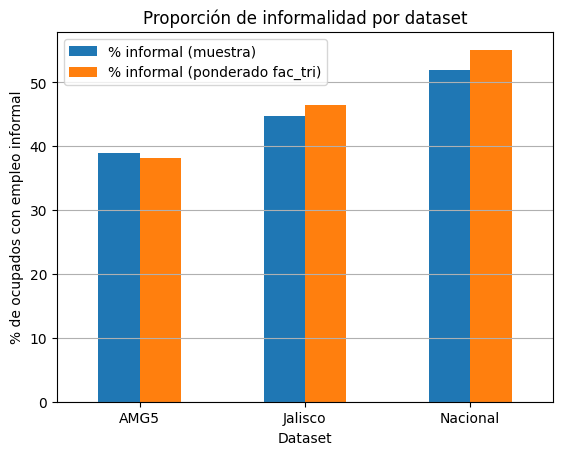

In [92]:
# Proporción de informales en la muestra (sin ponderar) y en la población (ponderada con fac_tri)
nombres = ["AMG5", "Jalisco", "Nacional"]
filas = []
informal_muestra = []
informal_ponderado = []
personas = []

for d in [df_amg5, df_jalisco, df_nacional]:
    filas.append(len(d))

    # muestra: promedio simple de y (cada persona cuenta igual)
    informal_muestra.append(round(100 * d["y"].mean(), 1))

    # población: cada persona pesa lo que indica su factor de expansión
    ponderado = (d["y"] * d["fac_tri"]).sum() / d["fac_tri"].sum()
    informal_ponderado.append(round(100 * ponderado, 1))

    # cuántas personas reales representa la muestra (en millones)
    personas.append(round(d["fac_tri"].sum() / 1000000, 2))

tabla_balance = pd.DataFrame({
    "Dataset": nombres,
    "Filas": filas,
    "% informal (muestra)": informal_muestra,
    "% informal (ponderado fac_tri)": informal_ponderado,
    "Personas representadas (millones)": personas
})
print(tabla_balance)

tabla_balance.plot.bar(x="Dataset", y=["% informal (muestra)", "% informal (ponderado fac_tri)"], rot=0)
plt.ylabel("% de ocupados con empleo informal")
plt.title("Proporción de informalidad por dataset")
plt.grid(axis="y")
plt.show()

#### Variables numéricas por condición de informalidad

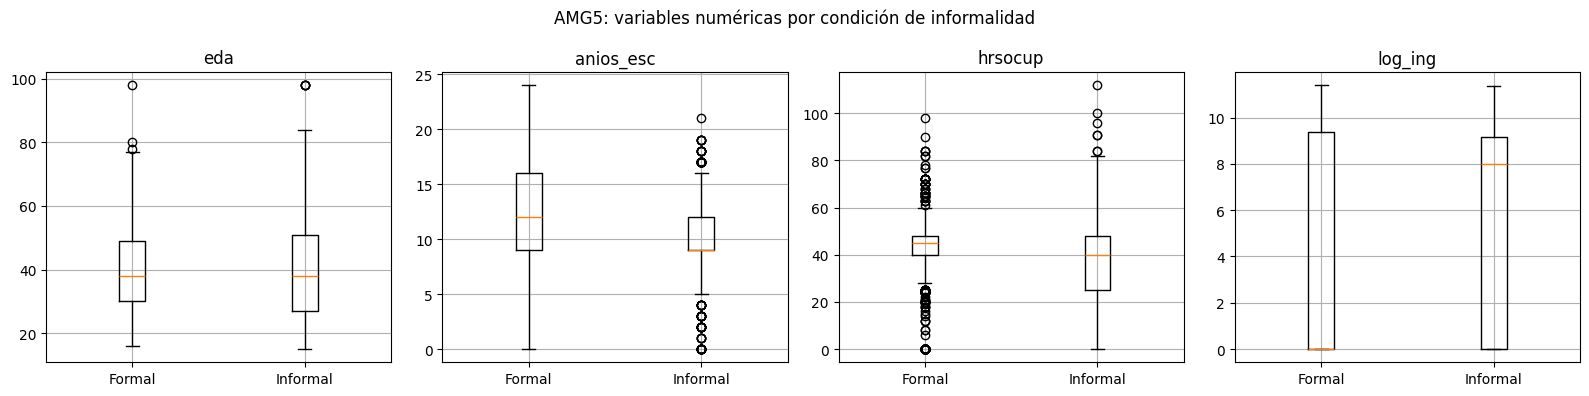

In [93]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

variables = ["eda", "anios_esc", "hrsocup", "log_ing"]
for i in range(4):
    var = variables[i]
    formal = df_amg5[df_amg5["y"] == 0][var]
    informal = df_amg5[df_amg5["y"] == 1][var]
    axes[i].boxplot([formal, informal])
    axes[i].set_xticks([1, 2])
    axes[i].set_xticklabels(["Formal", "Informal"])
    axes[i].set_title(var)
    axes[i].grid()

plt.suptitle("AMG5: variables numéricas por condición de informalidad")
plt.tight_layout()
plt.show()

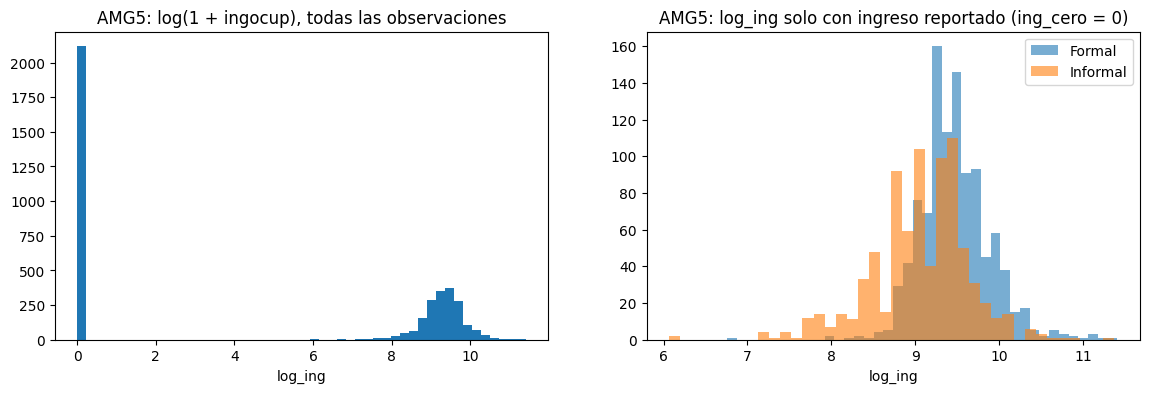

% de observaciones con ingocup = 0:
AMG5        53.5
Jalisco     47.7
Nacional    34.7
dtype: float64


In [94]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df_amg5["log_ing"], bins=50)
axes[0].set_title("AMG5: log(1 + ingocup), todas las observaciones")
axes[0].set_xlabel("log_ing")

con_ingreso = df_amg5[df_amg5["ing_cero"] == 0]
axes[1].hist(con_ingreso[con_ingreso["y"] == 0]["log_ing"], bins=40, alpha=0.6, label="Formal")
axes[1].hist(con_ingreso[con_ingreso["y"] == 1]["log_ing"], bins=40, alpha=0.6, label="Informal")
axes[1].set_title("AMG5: log_ing solo con ingreso reportado (ing_cero = 0)")
axes[1].set_xlabel("log_ing")
axes[1].legend()
plt.show()

print("% de observaciones con ingocup = 0:")
print(pd.Series({"AMG5": df_amg5["ing_cero"].mean(), "Jalisco": df_jalisco["ing_cero"].mean(),
                 "Nacional": df_nacional["ing_cero"].mean()}).mul(100).round(1))

#### ¿Qué significa `ingocup = 0`? Cruce con `ing7c`

`ingocup = 0` no siempre significa "no gana". Se cruza con `ing7c` (ingreso en rangos de salario mínimo: 1-5 rangos, 6 = **no recibe ingresos**, 7 = **no especificado**) para separar ambos casos y ver la tasa de informalidad en cada uno.

#### Tasa de informalidad por variable categórica

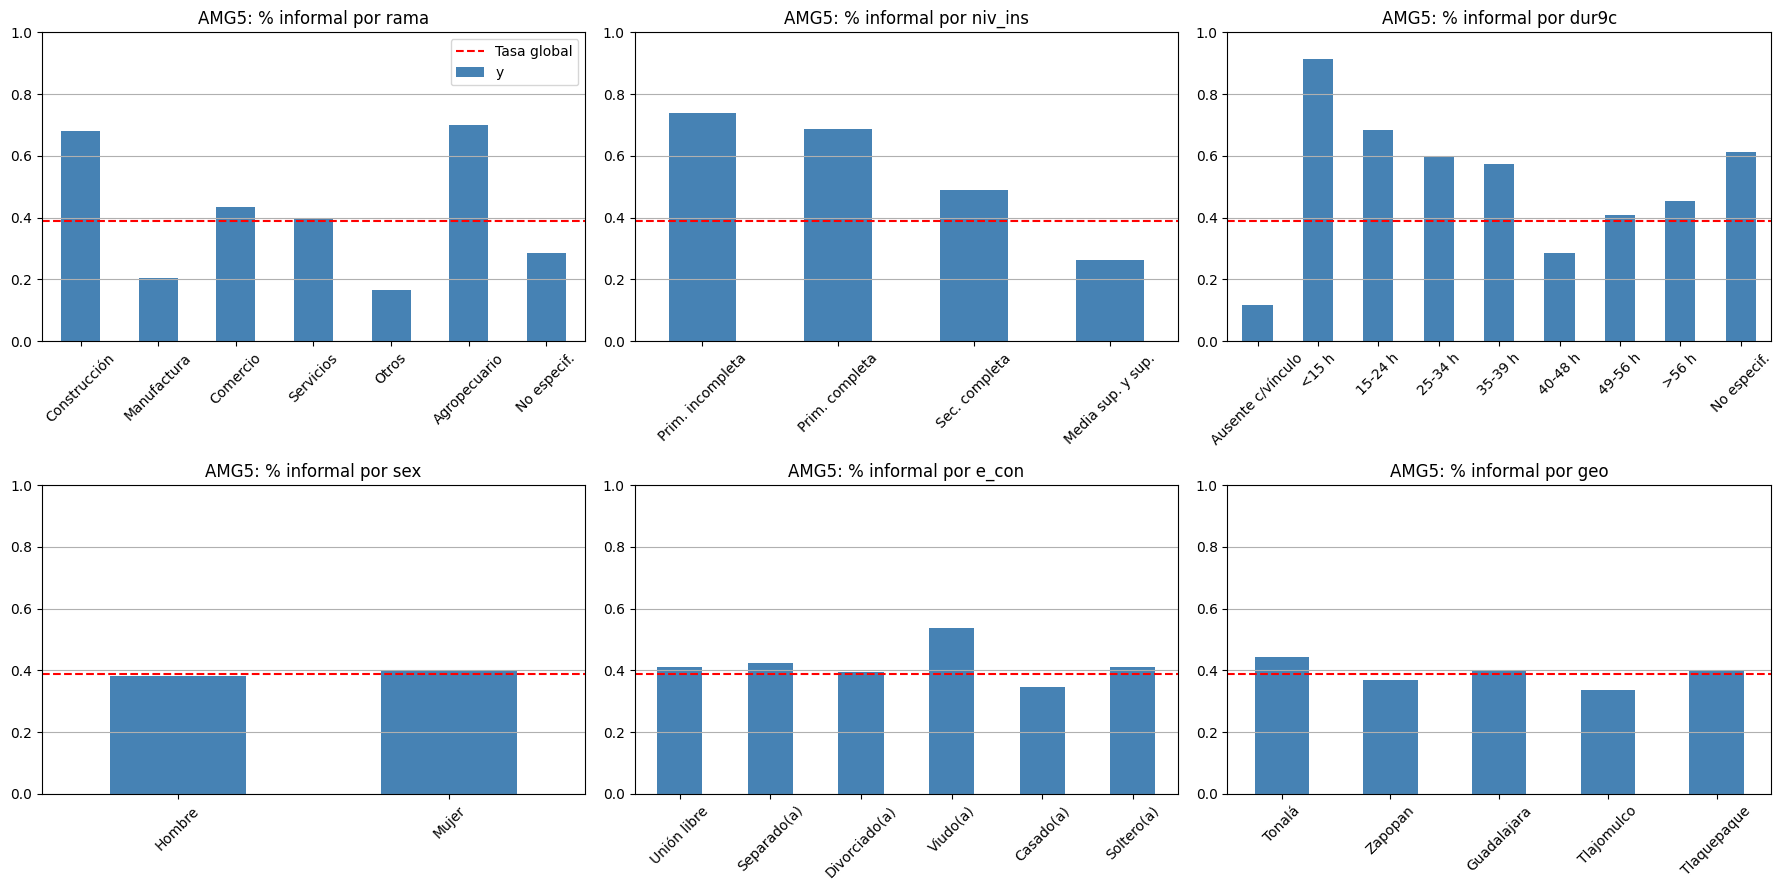

In [95]:
etiquetas = {
    "rama":    {"1": "Construcción", "2": "Manufactura", "3": "Comercio", "4": "Servicios",
                "5": "Otros", "6": "Agropecuario", "7": "No especif."},
    "niv_ins": {"1": "Prim. incompleta", "2": "Prim. completa", "3": "Sec. completa",
                "4": "Media sup. y sup.", "5": "No especif."},
    "dur9c":   {"1": "Ausente c/vínculo", "2": "<15 h", "3": "15-24 h", "4": "25-34 h", "5": "35-39 h",
                "6": "40-48 h", "7": "49-56 h", "8": ">56 h", "9": "No especif."},
    "sex":     {"1": "Hombre", "2": "Mujer"},
    "e_con":   {"1": "Unión libre", "2": "Separado(a)", "3": "Divorciado(a)", "4": "Viudo(a)",
                "5": "Casado(a)", "6": "Soltero(a)"},
    "geo":     {"39": "Guadalajara", "120": "Zapopan", "98": "Tlaquepaque", "101": "Tonalá", "97": "Tlajomulco"},
}

tasa_global = df_amg5["y"].mean()
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, var in zip(axes.flat, ["rama", "niv_ins", "dur9c", "sex", "e_con", "geo"]):
    tasa = df_amg5.groupby(var)["y"].mean().sort_index()
    tasa.index = [etiquetas[var].get(i, i) for i in tasa.index]
    tasa.plot.bar(ax=ax, color="steelblue")
    ax.axhline(tasa_global, color="red", linestyle="--", label="Tasa global")
    ax.set_title(f"AMG5: % informal por {var}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

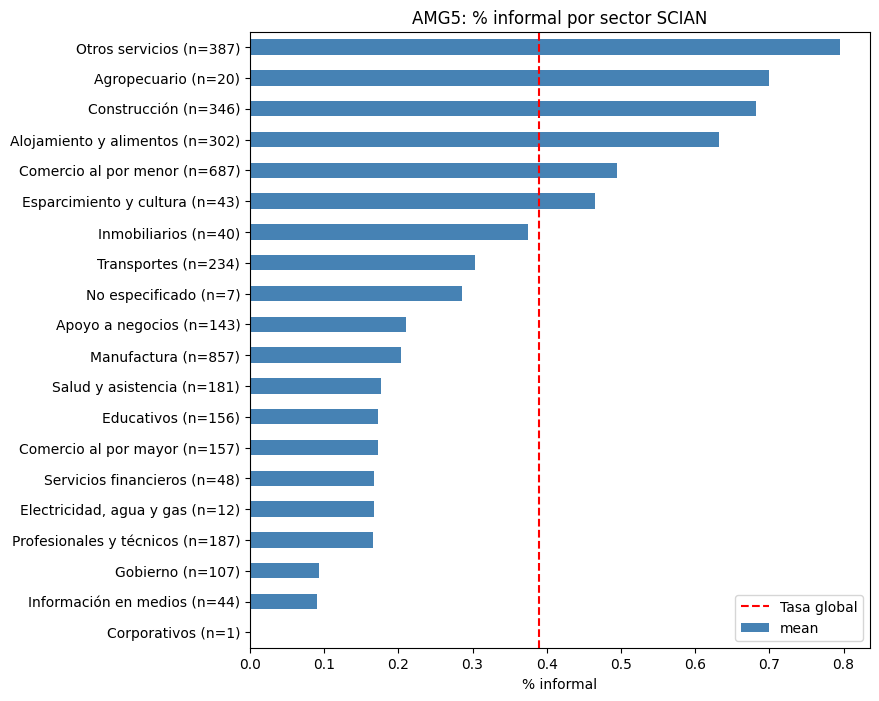

In [96]:
etiquetas_scian = {"1": "Agropecuario", "2": "Minería", "3": "Electricidad, agua y gas", "4": "Construcción",
                   "5": "Manufactura", "6": "Comercio al por mayor", "7": "Comercio al por menor",
                   "8": "Transportes", "9": "Información en medios", "10": "Servicios financieros",
                   "11": "Inmobiliarios", "12": "Profesionales y técnicos", "13": "Corporativos",
                   "14": "Apoyo a negocios", "15": "Educativos", "16": "Salud y asistencia",
                   "17": "Esparcimiento y cultura", "18": "Alojamiento y alimentos", "19": "Otros servicios",
                   "20": "Gobierno", "21": "No especificado"}

tasa_scian = df_amg5.groupby("scian")["y"].agg(["mean", "size"]).sort_values("mean")
tasa_scian.index = [etiquetas_scian.get(i, i) + f" (n={n})" for i, n in zip(tasa_scian.index, tasa_scian["size"])]
tasa_scian["mean"].plot.barh(figsize=(8, 8), color="steelblue")
plt.axvline(tasa_global, color="red", linestyle="--", label="Tasa global")
plt.xlabel("% informal")
plt.title("AMG5: % informal por sector SCIAN")
plt.legend()
plt.show()

#### Relación de la edad con la informalidad (¿forma de U?)

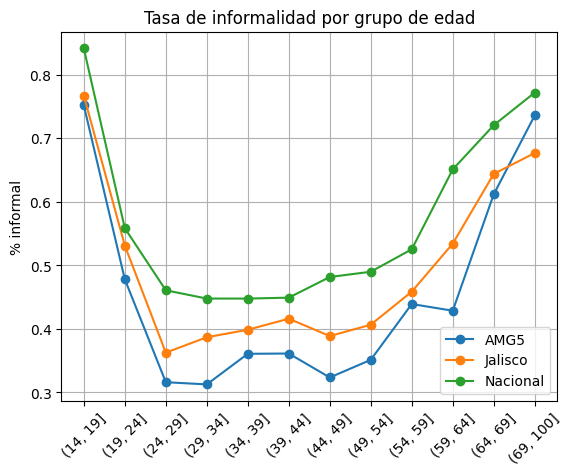

In [97]:
cortes = [14, 19, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 100]
for nombre, d in [("AMG5", df_amg5), ("Jalisco", df_jalisco), ("Nacional", df_nacional)]:
    tasa_edad = d.groupby(pd.cut(d["eda"], bins=cortes), observed=True)["y"].mean()
    plt.plot([str(i) for i in tasa_edad.index], tasa_edad.values, marker="o", label=nombre)
plt.xticks(rotation=45)
plt.ylabel("% informal")
plt.title("Tasa de informalidad por grupo de edad")
plt.legend()
plt.grid()
plt.show()

Si la curva tiene forma de U, la regresión logística solo con `eda` lineal no captura bien el efecto. Por eso en la ablación se prueba agregar `eda2`. La SVM y el MLP pueden captar esta forma por sí mismos.

#### Correlación entre variables numéricas

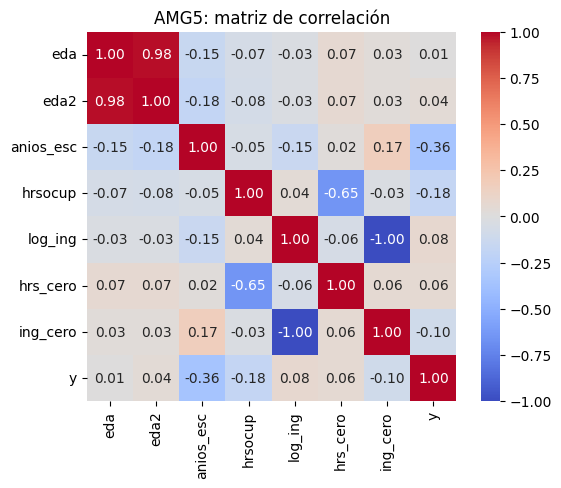

In [98]:
corr = df_amg5[["eda", "eda2", "anios_esc", "hrsocup", "log_ing", "hrs_cero", "ing_cero", "y"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("AMG5: matriz de correlación")
plt.show()

#### Informalidad por entidad federativa (nacional)

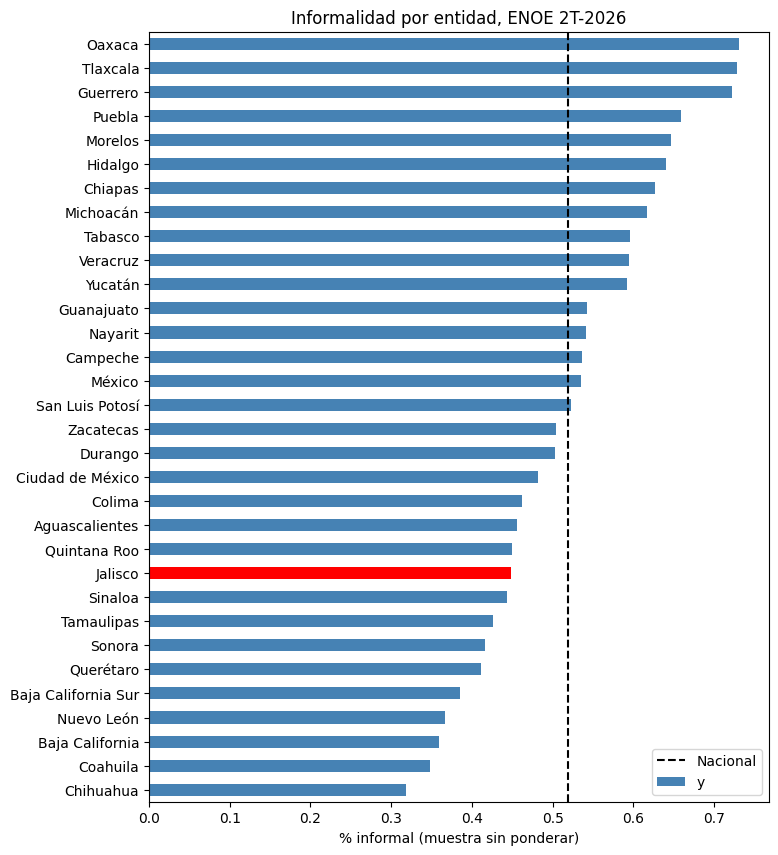

In [99]:
entidades = {1: "Aguascalientes", 2: "Baja California", 3: "Baja California Sur", 4: "Campeche", 5: "Coahuila",
             6: "Colima", 7: "Chiapas", 8: "Chihuahua", 9: "Ciudad de México", 10: "Durango", 11: "Guanajuato",
             12: "Guerrero", 13: "Hidalgo", 14: "Jalisco", 15: "México", 16: "Michoacán", 17: "Morelos",
             18: "Nayarit", 19: "Nuevo León", 20: "Oaxaca", 21: "Puebla", 22: "Querétaro", 23: "Quintana Roo",
             24: "San Luis Potosí", 25: "Sinaloa", 26: "Sonora", 27: "Tabasco", 28: "Tamaulipas", 29: "Tlaxcala",
             30: "Veracruz", 31: "Yucatán", 32: "Zacatecas"}

tasa_ent = df_nacional.groupby("cve_ent")["y"].mean().sort_values()
tasa_ent.index = [entidades[int(i)] for i in tasa_ent.index]
tasa_ent.plot.barh(figsize=(8, 10), color=["red" if i == "Jalisco" else "steelblue" for i in tasa_ent.index])
plt.axvline(df_nacional["y"].mean(), color="black", linestyle="--", label="Nacional")
plt.xlabel("% informal (muestra sin ponderar)")
plt.title("Informalidad por entidad, ENOE 2T-2026")
plt.legend()
plt.show()

## 4. Modelo propuesto

Se proponen tres modelos de complejidad creciente. Los tres comparten el mismo preprocesamiento (sección 5) y sus hiperparámetros se optimizan con **Optuna + `GPSampler`** (procesos gaussianos), maximizando el ROC-AUC promedio de una validación cruzada estratificada de `K_OPT = 5` *folds* sobre el conjunto de entrenamiento.

| Modelo | Hiperparámetro | Espacio de búsqueda | Escala |
|---|---|---|---|
| **Regresión logística (red elástica)** | `C` | $[10^{-4},\ 10^{2}]$ | logarítmica |
| | `l1_ratio` | $[0,\ 1]$ | lineal |
| **SVM, kernel RBF** | `C` | $[10^{-2},\ 10^{3}]$ | logarítmica |
| | `gamma` | $[10^{-4},\ 10^{1}]$ | logarítmica |
| **MLP** | `n_capas` | $\{1, 2\}$ | entera |
| | `neuronas_1`, `neuronas_2` | $[5,\ 100]$ | entera |
| | `alpha` | $[10^{-5},\ 1]$ | logarítmica |
| | `learning_rate_init` | $[10^{-4},\ 10^{-1}]$ | logarítmica |

Valores fijos:

- **Regresión logística:** `solver="saga"`, que es el que permite la red elástica.
- **SVM:** `cache_size=1000` para acelerar. No se usa `probability=True`, porque el ROC-AUC se calcula con `decision_function`.
- **MLP:** activación ReLU, optimizador Adam, `early_stopping=True` y `max_iter=500`.
- **Clases:** no se usa `class_weight`, porque el ROC-AUC no se ve afectado por el desbalance moderado.

Notas:

- **Escala logarítmica.** Los rangos de `C`, `gamma`, `alpha` y la tasa de aprendizaje abarcan varios órdenes de magnitud, así que se exploran en escala logarítmica (`log=True`). Así el GP dedica el mismo esfuerzo a $[0.001, 0.01]$ que a $[10, 100]$.
- **`neuronas_2` con una sola capa.** Cuando `n_capas = 1`, el valor de `neuronas_2` se propone pero no se usa. Se hace así porque `GPSampler` funciona mejor con un espacio de búsqueda fijo (sin parámetros condicionales).


In [100]:
def crear_preprocesador(num_cols, bin_cols, cat_cols):
    # Numéricas: imputar con la mediana y estandarizar
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categóricas: one-hot, una sola columna si es binaria y categorías raras (<1%) agrupadas
    categorical_transformer = OneHotEncoder(drop="if_binary", min_frequency=0.01,
                                            handle_unknown="infrequent_if_exist", sparse_output=False)

    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_transformer, num_cols),
        ("bin", "passthrough", bin_cols),      
        ("cat", categorical_transformer, cat_cols)
    ])
    return preprocessor

def armar_modelo(nombre, params):
    # Crea el Pipeline completo (preprocesamiento + modelo) con los hiperparámetros que se le pasen
    if nombre == "Regresión logística":
        modelo = LogisticRegression(C=params["C"], l1_ratio=params["l1_ratio"], solver="saga",
                                    max_iter=3000, random_state=SEMILLA)

    elif nombre == "SVM RBF":
        modelo = SVC(kernel="rbf", C=params["C"], gamma=params["gamma"], cache_size=1000)

    elif nombre == "MLP":
        # neuronas_2 solo se usa si la red tiene 2 capas
        if params["n_capas"] == 1:
            capas = (params["neuronas_1"],)
        else:
            capas = (params["neuronas_1"], params["neuronas_2"])
        modelo = MLPClassifier(hidden_layer_sizes=capas, alpha=params["alpha"],
                               learning_rate_init=params["learning_rate_init"],
                               early_stopping=True, max_iter=500, random_state=SEMILLA)

    pipe = Pipeline(steps=[
        ("preprocessor", crear_preprocesador(NUM_COLS, BIN_COLS, CAT_COLS)),
        ("modelo", modelo)
    ])
    return pipe


In [101]:
cv_opt = StratifiedKFold(n_splits=K_OPT, shuffle=True, random_state=SEMILLA)

# Espacio de búsqueda de cada modelo: (escala, mínimo, máximo)
espacios = {
    "Regresión logística": {"C": ("log", 1e-4, 1e2),
                            "l1_ratio": ("lineal", 0.0, 1.0)},
    "SVM RBF": {"C": ("log", 1e-2, 1e3),
                "gamma": ("log", 1e-4, 1e1)},
    "MLP": {"n_capas": ("entero", 1, 2),
            "neuronas_1": ("entero", 5, 100),
            "neuronas_2": ("entero", 5, 100),     # solo se usa si n_capas = 2
            "alpha": ("log", 1e-5, 1.0),
            "learning_rate_init": ("log", 1e-4, 1e-1)},
}


def convertir(u, espacio):
    # El GP trabaja con números entre 0 y 1; aquí se pasan a los valores reales de cada hiperparámetro
    params = {}
    i = 0
    for nombre_param in espacio:
        escala, bajo, alto = espacio[nombre_param]
        if escala == "log":
            exponente = np.log10(bajo) + u[i] * (np.log10(alto) - np.log10(bajo))
            params[nombre_param] = float(10 ** exponente)
        elif escala == "lineal":
            params[nombre_param] = float(bajo + u[i] * (alto - bajo))
        elif escala == "entero":
            params[nombre_param] = int(round(bajo + u[i] * (alto - bajo)))
        i = i + 1
    return params


def evaluar(nombre, params):
    # Función objetivo: ROC-AUC promedio de la validación cruzada con esos hiperparámetros
    modelo = armar_modelo(nombre, params)
    scores = cross_val_score(modelo, X_opt, y_opt, cv=cv_opt, scoring="roc_auc", n_jobs=-1)
    return scores.mean()


def optimizacion_bayesiana(nombre, n_iter, n_inicio, kappa=2, tiempo_max=None):
    espacio = espacios[nombre]
    d = len(espacio)                       # número de hiperparámetros
    rng = np.random.default_rng(SEMILLA)

    U = []              # puntos evaluados (escala 0-1)
    valores = []        # AUC de cada punto
    lista_params = []   # hiperparámetros reales de cada punto
    inicio = time.time()

    for i in range(n_iter):
        if i < n_inicio:
            # primeros puntos al azar (conocimiento previo)
            u = rng.uniform(0, 1, d)
        else:
            # ajustar el proceso gaussiano con todo lo evaluado hasta ahora
            kernel = 1 * RBF(length_scale=np.ones(d)) + WhiteKernel(noise_level=1e-4)
            gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                                          n_restarts_optimizer=5, random_state=SEMILLA)
            gp.fit(np.array(U), np.array(valores))

            # elegir el candidato con la banda superior más alta (media + kappa * sigma)
            candidatos = rng.uniform(0, 1, (5000, d))
            media, sigma = gp.predict(candidatos, return_std=True)
            y_upper = media + kappa * sigma
            u = candidatos[np.argmax(y_upper)]

        params = convertir(u, espacio)
        valor = evaluar(nombre, params)

        U.append(u)
        valores.append(valor)
        lista_params.append(params)
        print("Iteración", i + 1, "| AUC:", round(valor, 4), "|", params)

        if tiempo_max is not None and time.time() - inicio > tiempo_max:
            print("Se alcanzó el tiempo máximo")
            break

    mejor = np.argmax(valores)
    resultado = {"params": lista_params, "valores": valores, "U": np.array(U),
                 "best_params": lista_params[mejor], "best_value": valores[mejor]}
    return resultado

## 5. Pipeline

### 5.1 Diagrama

El diagrama resume el proceso completo, desde el archivo del INEGI hasta la evaluación final. Hay dos ideas clave:

1. Todo el preprocesamiento está dentro del `Pipeline`. El escalador y el codificador se ajustan solo con los folds de entrenamiento en cada iteración de la validación cruzada, así que no hay fuga de información.
2. La optimización bayesiana es un ciclo. El GP propone hiperparámetros, se evalúan con validación cruzada, el resultado actualiza el GP y se repite.

![Diagrama de flujo Pipeline](< /Users/claudioalejoencarnacionmartinez/Documents/SEMESTRE OTOÑO 2026/LAB APRENDIZAJE ESTADÍSTICO/LABORATORIO-DE-APRENDIZAJE-ESTAD-STICO/SEGUNDO PARCIAL/PROYECTO_02/PIPELINE_P02.png >)

### 5.2 Columnas que entran al modelo y división train/test

Las listas finales de predictoras se definen aquí. La división 80/20 estratificada de AMG5 y Jalisco también se hace aquí, para que la ablación de la sección 5.3 use solo el conjunto de entrenamiento: el conjunto de prueba no se toca hasta la evaluación final.

In [102]:
NUM_COLS = ["eda", "anios_esc", "hrsocup", "log_ing"]
BIN_COLS = ["hrs_cero", "ing_cero"]
CAT_COLS = ["sex", "e_con", "niv_ins", "cs_p12", "cs_p17", "t_loc_tri", "ur", "rama", "dur9c", "geo"]

# X conserva todas las columnas; el ColumnTransformer toma solo las que necesita (el resto se descarta)
X_amg = df_amg5.drop(columns=["y"])
y_amg = df_amg5["y"]
X_train_amg, X_test_amg, y_train_amg, y_test_amg = train_test_split(
    X_amg, y_amg, test_size=TEST_SIZE, stratify=y_amg, random_state=SEMILLA)

X_jal = df_jalisco.drop(columns=["y"])
y_jal = df_jalisco["y"]
X_train_jal, X_test_jal, y_train_jal, y_test_jal = train_test_split(
    X_jal, y_jal, test_size=TEST_SIZE, stratify=y_jal, random_state=SEMILLA)

print("AMG5    -> train:", X_train_amg.shape, " test:", X_test_amg.shape)
print("Jalisco -> train:", X_train_jal.shape, " test:", X_test_jal.shape)

AMG5    -> train: (3167, 23)  test: (792, 23)
Jalisco -> train: (4705, 23)  test: (1177, 23)


In [103]:
# columnas que resultan después del preprocesamiento (ejemplo con AMG5)
pre_ejemplo = crear_preprocesador(NUM_COLS, BIN_COLS, CAT_COLS)
pre_ejemplo.fit(X_train_amg)

nombres_columnas = pre_ejemplo.get_feature_names_out()
print("Número de columnas después del preprocesamiento:", len(nombres_columnas))
print(nombres_columnas)

Número de columnas después del preprocesamiento: 43
['num__eda' 'num__anios_esc' 'num__hrsocup' 'num__log_ing' 'bin__hrs_cero'
 'bin__ing_cero' 'cat__sex_2' 'cat__e_con_1' 'cat__e_con_2' 'cat__e_con_3'
 'cat__e_con_4' 'cat__e_con_5' 'cat__e_con_6' 'cat__niv_ins_1'
 'cat__niv_ins_2' 'cat__niv_ins_3' 'cat__niv_ins_4'
 'cat__cs_p12_infrequent_sklearn' 'cat__cs_p17_2' 'cat__t_loc_tri_1'
 'cat__t_loc_tri_2' 'cat__t_loc_tri_3' 'cat__t_loc_tri_4' 'cat__ur_2'
 'cat__rama_1' 'cat__rama_2' 'cat__rama_3' 'cat__rama_4'
 'cat__rama_infrequent_sklearn' 'cat__dur9c_1' 'cat__dur9c_2'
 'cat__dur9c_3' 'cat__dur9c_4' 'cat__dur9c_5' 'cat__dur9c_6'
 'cat__dur9c_7' 'cat__dur9c_8' 'cat__dur9c_9' 'cat__geo_101'
 'cat__geo_120' 'cat__geo_39' 'cat__geo_97' 'cat__geo_98']


### 5.3 Selección de variables: análisis de sensibilidad con regresión logística

Antes de la optimización se prueban variantes del conjunto de predictoras con una regresión logística con hiperparámetros por defecto. Se usa la CV de `K_FINAL` folds sobre el conjunto de entrenamiento de AMG5 y Jalisco:

| Variante | Qué evalúa |
|---|---|
| Base | `rama` y `ing_cero` (configuración propuesta) |
| Solo `scian` | Si la clasificación fina del sector aporta más que `rama` |
| `rama` + `scian` | Si conviene usar ambas |
| Sin `ing_cero` | Cuánto pesa la variable que funciona como proxy de la definición |
| Con `eda²` | Si la logística mejora al poder captar la forma de U de la edad |

In [104]:
cv_final = StratifiedKFold(n_splits=K_FINAL, shuffle=True, random_state=SEMILLA)

CAT_SIN_RAMA = [c for c in CAT_COLS if c != "rama"]
variantes = {
    "Base (rama, con ing_cero)": (NUM_COLS, BIN_COLS, CAT_COLS),
    "Solo scian":                (NUM_COLS, BIN_COLS, CAT_SIN_RAMA + ["scian"]),
    "rama + scian":              (NUM_COLS, BIN_COLS, CAT_COLS + ["scian"]),
    "Sin ing_cero":              (NUM_COLS, ["hrs_cero"], CAT_COLS),
    "Con eda²":                  (NUM_COLS + ["eda2"], BIN_COLS, CAT_COLS),
}

resultados_anal_sensi = []
for nombre_df, X_abl, y_abl in [("AMG5", X_train_amg, y_train_amg), ("Jalisco", X_train_jal, y_train_jal)]:
    for nombre, (num, binr, cat) in variantes.items():
        modelo = Pipeline(steps=[
            ("preprocessor", crear_preprocesador(num, binr, cat)),
            ("logit", LogisticRegression(max_iter=2000))
        ])
        scores = cross_val_score(modelo, X_abl, y_abl, cv=cv_final, scoring="roc_auc", n_jobs=-1)
        resultados_anal_sensi.append({
            "Dataset": nombre_df,
            "Variante": nombre,
            "AUC media": scores.mean(),
            "AUC std": scores.std()
        })

tabla_abl = pd.DataFrame(resultados_anal_sensi)
tabla_abl.pivot(index="Variante", columns="Dataset", values=["AUC media", "AUC std"]).round(4)

AUC media         AUC std        
Dataset                        AMG5 Jalisco    AMG5 Jalisco
Variante                                                   
Base (rama, con ing_cero)    0.7984  0.8168  0.0049  0.0073
Con eda²                     0.8014  0.8181  0.0060  0.0071
Sin ing_cero                 0.7947  0.8105  0.0053  0.0077
Solo scian                   0.8248  0.8411  0.0068  0.0073
rama + scian                 0.8242  0.8411  0.0069  0.0073

### 5.4 Decisión sobre las variables

- `scian` frente a `rama`: usar `scian` en lugar de `rama` aumentó el AUC de 0.7984 a 0.8248 en AMG5 (+0.026) y de 0.8168 a 0.8411 en Jalisco (+0.024), una mejora de entre 3 y 5 desviaciones estándar entre folds. Usar ambas no mejora a `scian` sola (0.8242 y 0.8411), lo que confirma que son redundantes. Decisión: `scian` sustituye a `rama`. La separación de los servicios en sectores específicos contiene señal que `rama` pierde al agruparlos.
- `ing_cero`: quitarla redujo el AUC en 0.004 (AMG5) y 0.006 (Jalisco), menos de una desviación estándar. El desempeño no depende de esta variable, que podría funcionar como proxy de la definición de informalidad. Se conserva porque aporta información legítima.
- `eda²`: la mejora fue de 0.003 (AMG5) y 0.001 (Jalisco), despreciable. Aunque la tasa de informalidad muestra forma de U con la edad, ese efecto queda capturado en buena medida por las demás variables. No se agrega, para que los tres modelos usen las mismas predictoras.

In [105]:
CAT_COLS.remove("rama")
CAT_COLS.append("scian")

print("Numéricas: ", NUM_COLS)
print("Binarias:  ", BIN_COLS)
print("Categóricas:", CAT_COLS)

pre_final = crear_preprocesador(NUM_COLS, BIN_COLS, CAT_COLS)
pre_final.fit(X_train_amg)
print("\nColumnas después del preprocesamiento (AMG5):", len(pre_final.get_feature_names_out()))

Numéricas:  ['eda', 'anios_esc', 'hrsocup', 'log_ing']
Binarias:   ['hrs_cero', 'ing_cero']
Categóricas: ['sex', 'e_con', 'niv_ins', 'cs_p12', 'cs_p17', 't_loc_tri', 'ur', 'dur9c', 'geo', 'scian']

Columnas después del preprocesamiento (AMG5): 54


## 6. Ajuste de modelos y comparación

Para cada conjunto de datos el procedimiento es:

1. Optimizar los hiperparámetros de los tres modelos con `GPSampler` (`N_TRIALS` evaluaciones, CV de `K_OPT` *folds* en entrenamiento).
2. Revisar la convergencia de la optimización.
3. Comparar los modelos con sus mejores hiperparámetros mediante CV de `K_FINAL` *folds* en entrenamiento: **media y desviación estándar** del ROC-AUC, más métricas complementarias.
4. Reentrenar con todo el conjunto de entrenamiento y evaluar en el conjunto de prueba (curvas ROC, matrices de confusión).

Primero se definen tres funciones auxiliares para no repetir el mismo código:

In [106]:
def graficar_convergencia(estudios, titulo):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    nombres = list(estudios.keys())

    for i in range(3):
        estudio = estudios[nombres[i]]

        # AUC de cada trial
        valores = estudio["valores"]

        # mejor AUC encontrado hasta cada trial
        mejor_hasta_ahora = []
        mejor = valores[0]
        for v in valores:
            if v > mejor:
                mejor = v
            mejor_hasta_ahora.append(mejor)

        iteraciones = range(1, len(valores) + 1)
        axes[i].plot(iteraciones, valores, "o", alpha=0.6, label="AUC de cada trial")
        axes[i].plot(iteraciones, mejor_hasta_ahora, color="red", label="Mejor AUC hasta el trial")
        axes[i].axvline(N_STARTUP + 0.5, color="gray", linestyle="--", label="Fin de trials aleatorios")
        axes[i].set_title(nombres[i])
        axes[i].set_xlabel("Trial")
        axes[i].set_ylabel("ROC-AUC (CV)")
        axes[i].grid()

    axes[0].legend()
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def evaluar_cv(estudios, X, y, X_svc, y_svc):
    # CV de K_FINAL folds con los mejores hiperparámetros de cada modelo.
    # La SVM usa X_svc, y_svc (en el nacional es una submuestra; en AMG5 y Jalisco son los mismos X, y)
    resultados = []
    scores_auc = {}
    modelos_finales = {}

    for nombre in estudios:
        if nombre == "SVM RBF":
            X_eval, y_eval = X_svc, y_svc
        else:
            X_eval, y_eval = X, y

        modelo = armar_modelo(nombre, estudios[nombre]["best_params"])
        scores = cross_validate(modelo, X_eval, y_eval, cv=cv_final, n_jobs=-1,
                                scoring=["roc_auc", "accuracy", "precision", "recall", "f1"])

        scores_auc[nombre] = scores["test_roc_auc"]
        resultados.append({
            "Modelo": nombre,
            "AUC media": scores["test_roc_auc"].mean(),
            "AUC std": scores["test_roc_auc"].std(),
            "Accuracy media": scores["test_accuracy"].mean(),
            "Precision media": scores["test_precision"].mean(),
            "Recall media": scores["test_recall"].mean(),
            "F1 media": scores["test_f1"].mean(),
            "n entrenamiento": len(y_eval)
        })

        # se reentrena con todo el entrenamiento para después evaluarlo en test
        modelo.fit(X_eval, y_eval)
        modelos_finales[nombre] = modelo

    tabla = pd.DataFrame(resultados).sort_values("AUC media", ascending=False)
    return tabla, scores_auc, modelos_finales


def evaluar_test(modelos, X_test, y_test, titulo):
    # Curvas ROC de los tres modelos en la misma gráfica
    fig, ax = plt.subplots(figsize=(6, 6))
    for nombre in modelos:
        RocCurveDisplay.from_estimator(modelos[nombre], X_test, y_test, name=nombre, ax=ax)
    ax.plot([0, 1], [0, 1], "k--", label="Azar")
    ax.set_title("Curvas ROC en test - " + titulo)
    ax.grid()
    ax.legend()
    plt.show()

    # Matrices de confusión y métricas
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    nombres = list(modelos.keys())
    resultados = []

    for i in range(3):
        nombre = nombres[i]
        modelo = modelos[nombre]
        y_pred = modelo.predict(X_test)

        # la SVM no da probabilidades, se usa su distancia al hiperplano para el AUC
        if nombre == "MLP":
            puntaje = modelo.predict_proba(X_test)[:, 1]
        else:
            puntaje = modelo.decision_function(X_test)

        mat = confusion_matrix(y_test, y_pred)
        TN, FP, FN, TP = mat.ravel()
        sns.heatmap(mat, annot=True, fmt="d", cbar=False, ax=axes[i],
                    xticklabels=["Formal", "Informal"], yticklabels=["Formal", "Informal"])
        axes[i].set_xlabel("Predicho")
        axes[i].set_ylabel("Real")
        axes[i].set_title(nombre)

        resultados.append({
            "Modelo": nombre,
            "ROC-AUC": roc_auc_score(y_test, puntaje),
            "Accuracy": (TP + TN) / (TP + TN + FP + FN),
            "Precision": TP / (TP + FP),
            "Recall": TP / (TP + FN),
            "Specificity": TN / (TN + FP),
            "F1": f1_score(y_test, y_pred)
        })

        print("=====", nombre, "=====")
        print(classification_report(y_test, y_pred, target_names=["Formal", "Informal"]))

    plt.suptitle("Matrices de confusión en test - " + titulo)
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(resultados).sort_values("ROC-AUC", ascending=False)

### 6.1 Área Metropolitana de Guadalajara (AMG5)

En este conjunto cada modelo se optimiza en su propia celda, para poder revisar con calma lo que propone el GP.

#### 6.1.1 Regresión logística con regularización (red elástica)

In [107]:
X_opt, y_opt = X_train_amg, y_train_amg
print("Optimizando con:", X_opt.shape)

estudios_amg = {}
tiempos_amg = {}

inicio = time.time()
res_logit = optimizacion_bayesiana("Regresión logística", N_TRIALS, N_STARTUP)
tiempo_logit = (time.time() - inicio) / 60

estudios_amg["Regresión logística"] = res_logit
tiempos_amg["Regresión logística"] = tiempo_logit

print("\nMejores hiperparámetros:", res_logit["best_params"])
print("Mejor ROC-AUC CV:", round(res_logit["best_value"], 4))
print("Tiempo (min):", round(tiempo_logit, 1))

Optimizando con: (3167, 23)
Iteración 1 | AUC: 0.8131 | {'C': 0.030618858757930332, 'l1_ratio': 0.12693830220007574}
Iteración 2 | AUC: 0.8222 | {'C': 0.12131380229291071, 'l1_ratio': 0.2972426218018579}
Iteración 3 | AUC: 0.8217 | {'C': 0.12127625123557303, 'l1_ratio': 0.6026882067116579}
Iteración 4 | AUC: 0.8215 | {'C': 0.12223891096559154, 'l1_ratio': 0.8141298423389511}

Mejores hiperparámetros: {'C': 0.12131380229291071, 'l1_ratio': 0.2972426218018579}
Mejor ROC-AUC CV: 0.8222
Tiempo (min): 0.0


#### 6.1.2 Máquina de vectores de soporte con kernel RBF

In [108]:
inicio = time.time()
res_svc = optimizacion_bayesiana("SVM RBF", N_TRIALS, N_STARTUP)
tiempo_svc = (time.time() - inicio) / 60

estudios_amg["SVM RBF"] = res_svc
tiempos_amg["SVM RBF"] = tiempo_svc

print("\nMejores hiperparámetros:", res_svc["best_params"])
print("Mejor ROC-AUC CV:", round(res_svc["best_value"], 4))
print("Tiempo (min):", round(tiempo_svc, 1))

Iteración 1 | AUC: 0.7781 | {'C': 1.1793901586457847, 'gamma': 0.00043121266809724576}
Iteración 2 | AUC: 0.8198 | {'C': 3.7147122593264403, 'gamma': 0.0030634663128348465}
Iteración 3 | AUC: 0.8103 | {'C': 3.7137540352209957, 'gamma': 0.1031433026855151}
Iteración 4 | AUC: 0.8152 | {'C': 3.7343941956925537, 'gamma': 0.0016328444595156357}

Mejores hiperparámetros: {'C': 3.7147122593264403, 'gamma': 0.0030634663128348465}
Mejor ROC-AUC CV: 0.8198
Tiempo (min): 0.1


#### 6.1.3 Perceptrón multicapa (MLP)

In [109]:
inicio = time.time()
res_mlp = optimizacion_bayesiana("MLP", N_TRIALS, N_STARTUP)
tiempo_mlp = (time.time() - inicio) / 60

estudios_amg["MLP"] = res_mlp
tiempos_amg["MLP"] = tiempo_mlp

print("\nMejores hiperparámetros:", res_mlp["best_params"])
print("Mejor ROC-AUC CV:", round(res_mlp["best_value"], 4))
print("Tiempo (min):", round(tiempo_mlp, 1))

Iteración 1 | AUC: 0.815 | {'n_capas': 1, 'neuronas_1': 17, 'neuronas_2': 54, 'alpha': 0.00030634663128348467, 'learning_rate_init': 0.006224591510250551}
Iteración 2 | AUC: 0.8136 | {'n_capas': 1, 'neuronas_1': 34, 'neuronas_2': 39, 'alpha': 2.770656921914186e-05, 'learning_rate_init': 0.054535907993812964}
Iteración 3 | AUC: 0.8166 | {'n_capas': 2, 'neuronas_1': 98, 'neuronas_2': 53, 'alpha': 0.0003420167230366684, 'learning_rate_init': 0.005290469650945471}
Iteración 4 | AUC: 0.8058 | {'n_capas': 1, 'neuronas_1': 98, 'neuronas_2': 12, 'alpha': 0.0002220780610996444, 'learning_rate_init': 0.059899546463513344}

Mejores hiperparámetros: {'n_capas': 2, 'neuronas_1': 98, 'neuronas_2': 53, 'alpha': 0.0003420167230366684, 'learning_rate_init': 0.005290469650945471}
Mejor ROC-AUC CV: 0.8166
Tiempo (min): 0.1


#### 6.1.4 Convergencia de la optimización bayesiana

La línea roja es el mejor AUC encontrado hasta cada *trial*. A la izquierda de la línea gris los *trials* son aleatorios; a la derecha los propone el GP. Si la línea roja se estabiliza, más *trials* probablemente no mejorarían mucho.

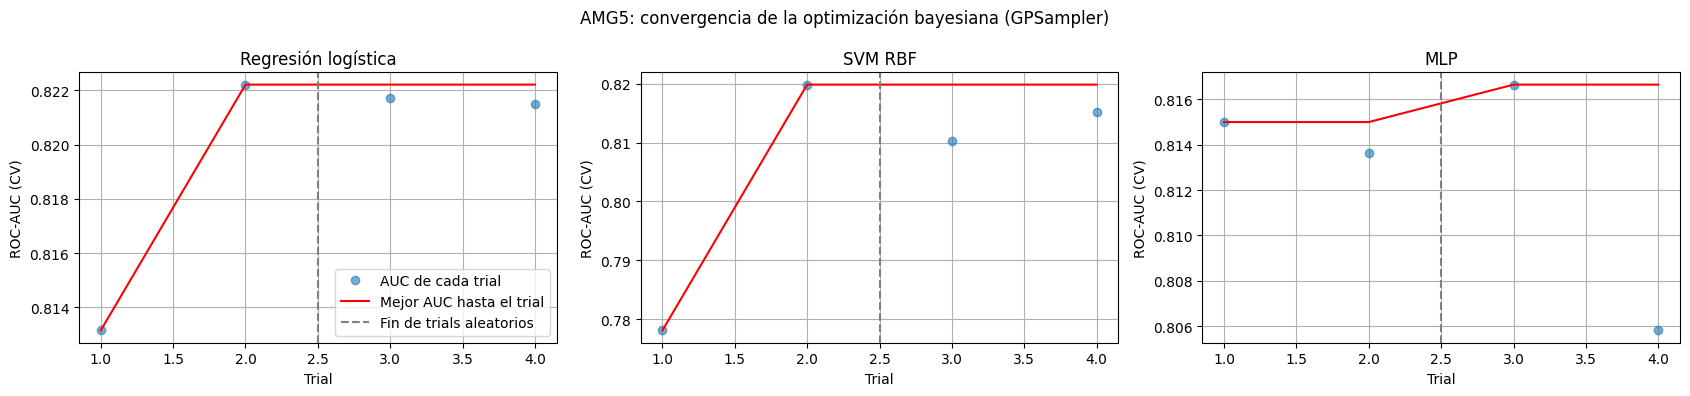

,Regresión logística,SVM RBF,MLP
Mejor AUC (CV opt.),0.8222,0.8198,0.8166
Iteraciones,4.0000,4.0000,4.0000
Tiempo (min),0.0267,0.1198,0.0530


In [110]:
graficar_convergencia(estudios_amg, "AMG5: convergencia de la optimización bayesiana (GPSampler)")

pd.DataFrame({nombre: [res["best_value"], len(res["valores"]), tiempos_amg[nombre]]
              for nombre, res in estudios_amg.items()},
             index=["Mejor AUC (CV opt.)", "Iteraciones", "Tiempo (min)"]).round(4)

#### 6.1.5 Comparación con validación cruzada de 10 *folds*

In [111]:
tabla_amg, scores_amg, modelos_amg = evaluar_cv(estudios_amg, X_train_amg, y_train_amg, X_train_amg, y_train_amg)
tabla_amg.round(4)

,Modelo,AUC media,AUC std,Accuracy media,Precision media,Recall media,F1 media,n entrenamiento
0,Regresión logística,0.8222,0.0072,0.7610,0.7344,0.6061,0.6639,3167
1,SVM RBF,0.8198,0.0060,0.7600,0.7682,0.5502,0.6408,3167
2,MLP,0.8166,0.0034,0.7569,0.7338,0.5932,0.6548,3167


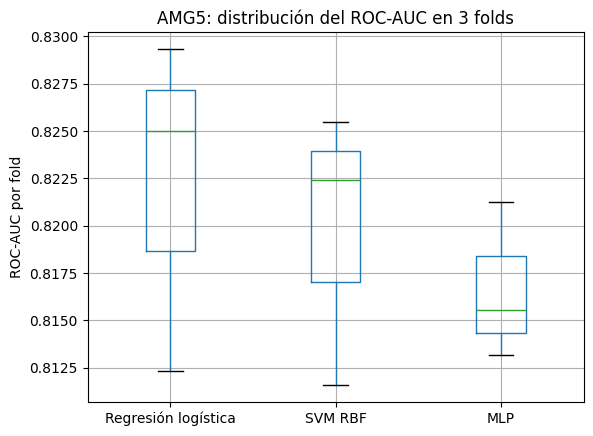

In [112]:
pd.DataFrame(scores_amg).boxplot()
plt.ylabel("ROC-AUC por fold")
plt.title(f"AMG5: distribución del ROC-AUC en {K_FINAL} folds")
plt.show()

#### 6.1.6 Evaluación en el conjunto de test

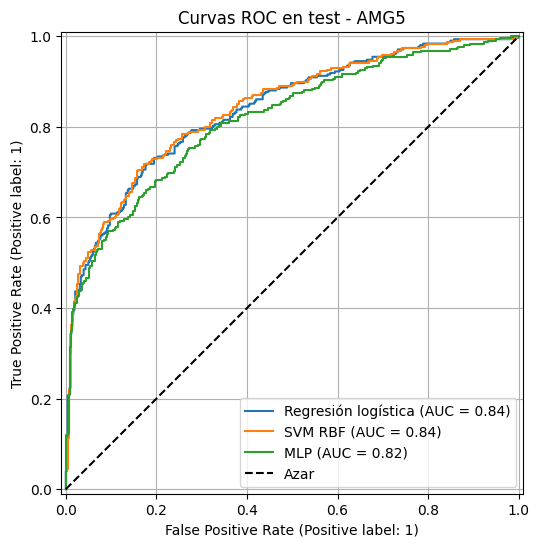

===== Regresión logística =====
              precision    recall  f1-score   support

      Formal       0.78      0.88      0.83       483
    Informal       0.77      0.61      0.68       309

    accuracy                           0.78       792
   macro avg       0.77      0.75      0.75       792
weighted avg       0.77      0.78      0.77       792

===== SVM RBF =====
              precision    recall  f1-score   support

      Formal       0.77      0.92      0.84       483
    Informal       0.82      0.58      0.68       309

    accuracy                           0.79       792
   macro avg       0.80      0.75      0.76       792
weighted avg       0.79      0.79      0.78       792

===== MLP =====
              precision    recall  f1-score   support

      Formal       0.76      0.92      0.83       483
    Informal       0.81      0.54      0.65       309

    accuracy                           0.77       792
   macro avg       0.79      0.73      0.74       792
weight

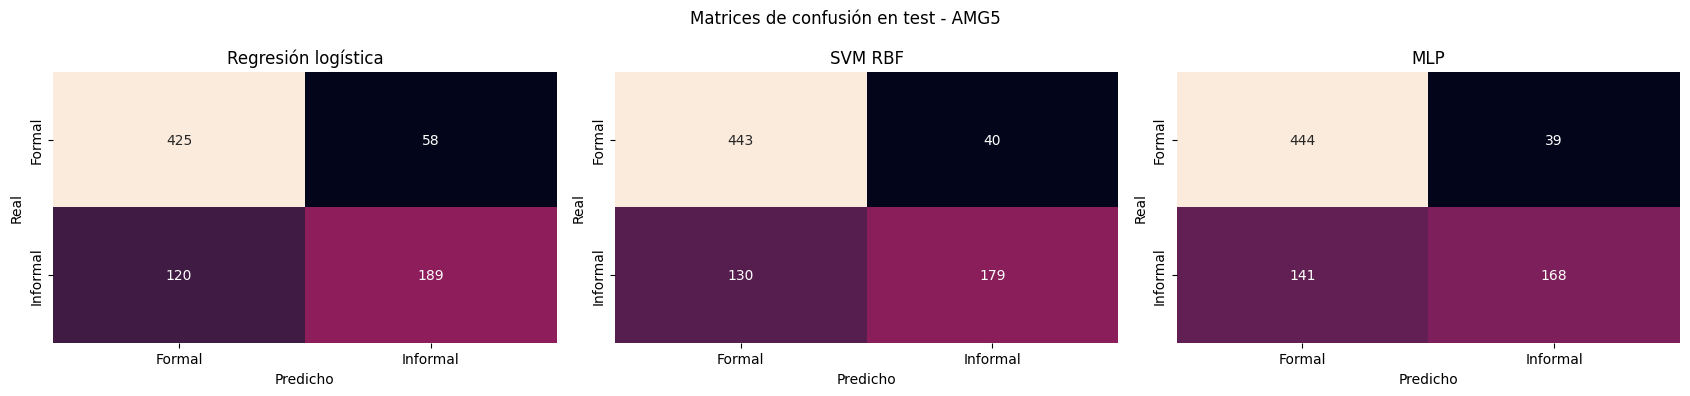

,Modelo,ROC-AUC,Accuracy,Precision,Recall,Specificity,F1
1,SVM RBF,0.8424,0.7854,0.8174,0.5793,0.9172,0.6780
0,Regresión logística,0.8390,0.7753,0.7652,0.6117,0.8799,0.6799
2,MLP,0.8178,0.7727,0.8116,0.5437,0.9193,0.6512


In [113]:
test_amg = evaluar_test(modelos_amg, X_test_amg, y_test_amg, "AMG5")
test_amg.round(4)

**Cómo leer la tabla:**

- Las numéricas están estandarizadas, así que su *odds ratio* corresponde al aumento de **una desviación estándar**.
- Para una categórica, el *odds ratio* compara esa categoría contra la de referencia: la primera categoría frecuente, que es la que no aparece en la tabla. Por ejemplo, `cat__scian_7` (comercio al por menor) contra el primer sector que no aparece.
- Las categorías raras quedan agrupadas en `..._infrequent_sklearn`.
- *Odds ratio* > 1 significa mayores momios de informalidad; < 1, menores.
- **`log_ing` e `ing_cero` deben leerse juntas.** Como `log_ing = 0` siempre que `ing_cero = 1`, sus coeficientes por separado pueden salir enormes y con signos que parecen contraintuitivos. El efecto de "no reportar ingreso" es la suma $\beta_{ing\_cero} + \beta_{log\_ing}\cdot z_0$, donde $z_0$ es el valor estandarizado de `log_ing = 0`. Lo mismo ocurre con `niv_ins` y `anios_esc`, que están muy correlacionadas.

**Interpretación (completar):** ¿coinciden los signos con lo esperado en la sección 3.6 (escolaridad negativa; agropecuario, construcción, jornadas cortas e `ing_cero` positivos)?

### 6.2 Jalisco

Se repite exactamente el mismo proceso, ahora con los tres modelos en un solo ciclo. Jalisco agrega municipios rurales y localidades pequeñas, así que `ur` y `t_loc_tri` ya tienen variación.

In [114]:
X_opt, y_opt = X_train_jal, y_train_jal
print("Optimizando con:", X_opt.shape)

estudios_jal = {}
tiempos_jal = {}

for nombre in espacios:
    print("=====", nombre, "=====")
    inicio = time.time()
    estudios_jal[nombre] = optimizacion_bayesiana(nombre, N_TRIALS, N_STARTUP)
    tiempos_jal[nombre] = (time.time() - inicio) / 60
    print("Mejores hiperparámetros:", estudios_jal[nombre]["best_params"])
    print("Mejor ROC-AUC CV:", round(estudios_jal[nombre]["best_value"], 4), "| Tiempo (min):", round(tiempos_jal[nombre], 1), "\n")

Optimizando con: (4705, 23)
===== Regresión logística =====
Iteración 1 | AUC: 0.8269 | {'C': 0.030618858757930332, 'l1_ratio': 0.12693830220007574}
Iteración 2 | AUC: 0.8355 | {'C': 0.12131380229291071, 'l1_ratio': 0.2972426218018579}
Iteración 3 | AUC: 0.8343 | {'C': 0.12127625123557303, 'l1_ratio': 0.6026882067116579}
Iteración 4 | AUC: 0.8358 | {'C': 0.12208552952504159, 'l1_ratio': 0.2425889633905295}
Mejores hiperparámetros: {'C': 0.12208552952504159, 'l1_ratio': 0.2425889633905295}
Mejor ROC-AUC CV: 0.8358 | Tiempo (min): 0.0 

===== SVM RBF =====
Iteración 1 | AUC: 0.7894 | {'C': 1.1793901586457847, 'gamma': 0.00043121266809724576}
Iteración 2 | AUC: 0.8334 | {'C': 3.7147122593264403, 'gamma': 0.0030634663128348465}
Iteración 3 | AUC: 0.8287 | {'C': 3.7137540352209957, 'gamma': 0.1031433026855151}
Iteración 4 | AUC: 0.8288 | {'C': 3.7343941956925537, 'gamma': 0.0016328444595156357}
Mejores hiperparámetros: {'C': 3.7147122593264403, 'gamma': 0.0030634663128348465}
Mejor ROC-AUC 

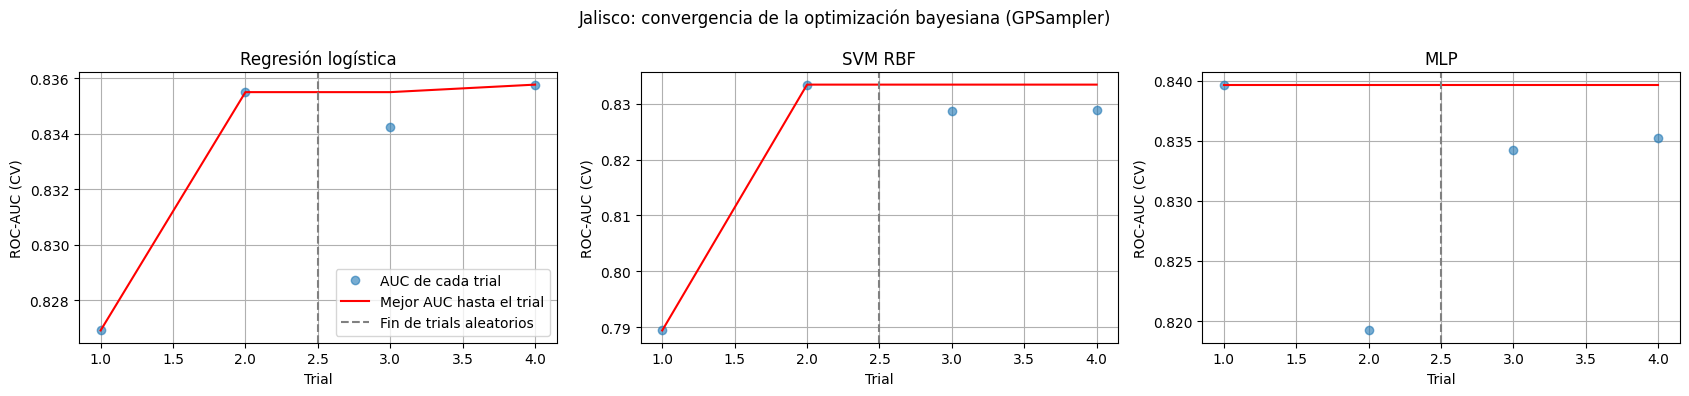

In [115]:
graficar_convergencia(estudios_jal, "Jalisco: convergencia de la optimización bayesiana (GPSampler)")

In [116]:
tabla_jal, scores_jal, modelos_jal = evaluar_cv(estudios_jal, X_train_jal, y_train_jal, X_train_jal, y_train_jal)
tabla_jal.round(4)

,Modelo,AUC media,AUC std,Accuracy media,Precision media,Recall media,F1 media,n entrenamiento
2,MLP,0.8397,0.0039,0.7668,0.7545,0.7119,0.7322,4705
0,Regresión logística,0.8358,0.0092,0.7624,0.7577,0.6910,0.7227,4705
1,SVM RBF,0.8334,0.0103,0.7617,0.7617,0.6820,0.7195,4705


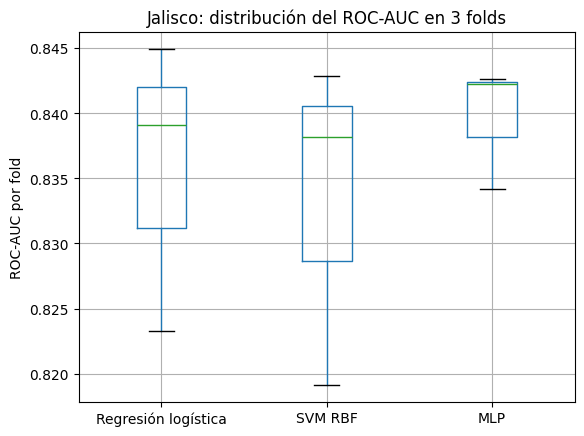

In [117]:
pd.DataFrame(scores_jal).boxplot()
plt.ylabel("ROC-AUC por fold")
plt.title(f"Jalisco: distribución del ROC-AUC en {K_FINAL} folds")
plt.show()

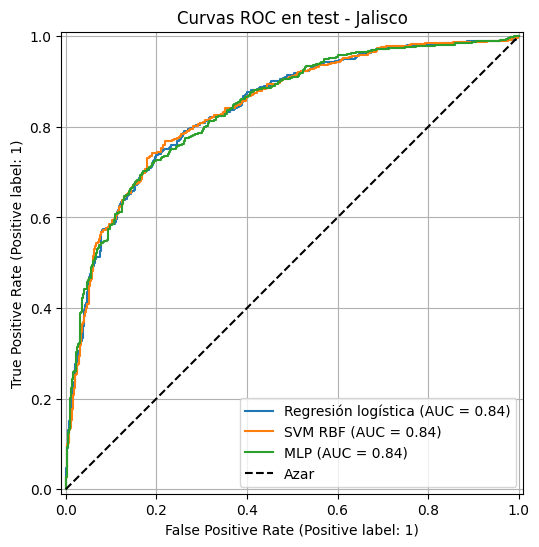

===== Regresión logística =====
              precision    recall  f1-score   support

      Formal       0.77      0.83      0.80       650
    Informal       0.77      0.70      0.73       527

    accuracy                           0.77      1177
   macro avg       0.77      0.76      0.77      1177
weighted avg       0.77      0.77      0.77      1177

===== SVM RBF =====
              precision    recall  f1-score   support

      Formal       0.77      0.83      0.80       650
    Informal       0.77      0.69      0.73       527

    accuracy                           0.77      1177
   macro avg       0.77      0.76      0.76      1177
weighted avg       0.77      0.77      0.77      1177

===== MLP =====
              precision    recall  f1-score   support

      Formal       0.78      0.81      0.79       650
    Informal       0.75      0.72      0.74       527

    accuracy                           0.77      1177
   macro avg       0.77      0.76      0.77      1177
weight

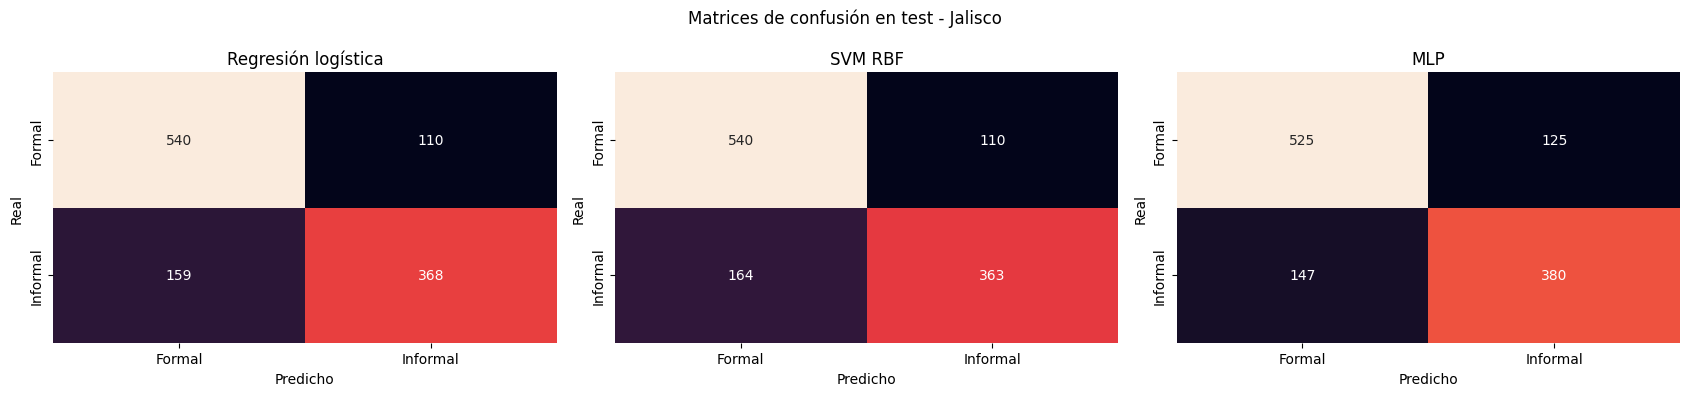

,Modelo,ROC-AUC,Accuracy,Precision,Recall,Specificity,F1
1,SVM RBF,0.8414,0.7672,0.7674,0.6888,0.8308,0.7260
0,Regresión logística,0.8409,0.7715,0.7699,0.6983,0.8308,0.7323
2,MLP,0.8407,0.7689,0.7525,0.7211,0.8077,0.7364


In [118]:
test_jal = evaluar_test(modelos_jal, X_test_jal, y_test_jal, "Jalisco")
test_jal.round(4)

### 6.3 Nacional

Este es el conjunto costoso (~189 mil ocupados). Decisiones:

- **`geo` = entidad federativa** (32 categorías), porque la clave de municipio se repite entre estados.
- **La SVM se optimiza y evalúa con una submuestra estratificada de `N_SVC_NACIONAL` observaciones** del conjunto de entrenamiento. Su costo de entrenamiento crece entre $n^2$ y $n^3$: con todo el conjunto, cada *trial* de 5 *folds* tardaría horas y la búsqueda completa días. La regresión logística y el MLP usan todo el entrenamiento. **Las tres se evalúan sobre el mismo conjunto de prueba completo**, así que la comparación final es justa en cuanto a la evaluación.
- **Persistencia:** los *trials* se guardan en `optuna_nacional.db` (SQLite). Si la corrida se interrumpe, al volver a ejecutar la celda Optuna carga lo ya hecho y solo corre los *trials* que faltan. Si cambias el espacio de búsqueda o las variables, **borra ese archivo** antes de volver a correr.
- **Tope de tiempo:** cada estudio se detiene al llegar a `N_TRIALS` o a `TIMEOUT_NACIONAL` segundos, lo que ocurra primero.

In [119]:
if MUESTRA_NACIONAL is not None:
    df_nac_modelo, _ = train_test_split(df_nacional, train_size=MUESTRA_NACIONAL,
                                        stratify=df_nacional["y"], random_state=SEMILLA)
else:
    df_nac_modelo = df_nacional

X_nac = df_nac_modelo.drop(columns=["y"])
y_nac = df_nac_modelo["y"]
X_train_nac, X_test_nac, y_train_nac, y_test_nac = train_test_split(
    X_nac, y_nac, test_size=TEST_SIZE, stratify=y_nac, random_state=SEMILLA)

# submuestra estratificada del entrenamiento solo para la SVM
if len(y_train_nac) > N_SVC_NACIONAL:
    X_train_svc_nac, _, y_train_svc_nac, _ = train_test_split(
        X_train_nac, y_train_nac, train_size=N_SVC_NACIONAL, stratify=y_train_nac, random_state=SEMILLA)
else:
    X_train_svc_nac, y_train_svc_nac = X_train_nac, y_train_nac

print("Nacional -> train:", X_train_nac.shape, " test:", X_test_nac.shape)
print("Submuestra SVM:", X_train_svc_nac.shape, "| % informal:", round(100 * y_train_svc_nac.mean(), 1))

Nacional -> train: (12000, 23)  test: (3000, 23)
Submuestra SVM: (3000, 23) | % informal: 51.9


In [120]:
estudios_nac = {}
tiempos_nac = {}

for nombre in espacios:
    if nombre == "SVM RBF":
        X_opt, y_opt = X_train_svc_nac, y_train_svc_nac
    else:
        X_opt, y_opt = X_train_nac, y_train_nac

    archivo = "resultado_nacional_" + nombre.replace(" ", "_") + ".pkl"
    print("=====", nombre, "| datos:", X_opt.shape, "=====")

    if os.path.exists(archivo):
        # ya se había optimizado en una corrida anterior
        estudios_nac[nombre] = pd.read_pickle(archivo)
        tiempos_nac[nombre] = 0
        print("Cargado desde", archivo)
    else:
        inicio = time.time()
        estudios_nac[nombre] = optimizacion_bayesiana(nombre, N_TRIALS, N_STARTUP, tiempo_max=TIMEOUT_NACIONAL)
        tiempos_nac[nombre] = (time.time() - inicio) / 60
        pd.to_pickle(estudios_nac[nombre], archivo)

    print("Mejores hiperparámetros:", estudios_nac[nombre]["best_params"])
    print("Mejor ROC-AUC CV:", round(estudios_nac[nombre]["best_value"], 4), "| Tiempo (min):", round(tiempos_nac[nombre], 1), "\n")

===== Regresión logística | datos: (12000, 23) =====
Cargado desde resultado_nacional_Regresión_logística.pkl
Mejores hiperparámetros: {'C': 0.12127625123557303, 'l1_ratio': 0.6026882067116579}
Mejor ROC-AUC CV: 0.8655 | Tiempo (min): 0 

===== SVM RBF | datos: (3000, 23) =====
Cargado desde resultado_nacional_SVM_RBF.pkl
Mejores hiperparámetros: {'C': 3.7147122593264403, 'gamma': 0.0030634663128348465}
Mejor ROC-AUC CV: 0.8445 | Tiempo (min): 0 

===== MLP | datos: (12000, 23) =====
Cargado desde resultado_nacional_MLP.pkl
Mejores hiperparámetros: {'n_capas': 2, 'neuronas_1': 82, 'neuronas_2': 52, 'alpha': 0.0006296595032002178, 'learning_rate_init': 0.0034688918503265878}
Mejor ROC-AUC CV: 0.8674 | Tiempo (min): 0 



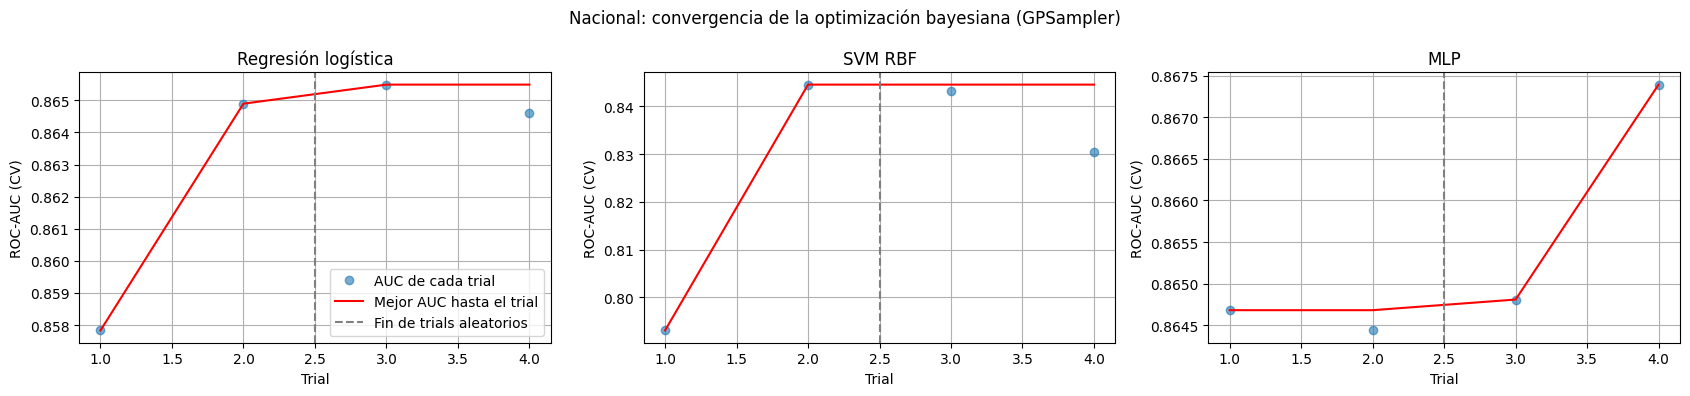

In [121]:
graficar_convergencia(estudios_nac, "Nacional: convergencia de la optimización bayesiana (GPSampler)")

In [122]:
tabla_nac, scores_nac, modelos_nac = evaluar_cv(estudios_nac, X_train_nac, y_train_nac,
                                                X_svc=X_train_svc_nac, y_svc=y_train_svc_nac)
tabla_nac.round(4)

,Modelo,AUC media,AUC std,Accuracy media,Precision media,Recall media,F1 media,n entrenamiento
2,MLP,0.8674,0.0043,0.7891,0.8088,0.7779,0.7930,12000
0,Regresión logística,0.8655,0.0034,0.7907,0.8059,0.7866,0.7961,12000
1,SVM RBF,0.8445,0.0097,0.7683,0.7909,0.7529,0.7714,3000


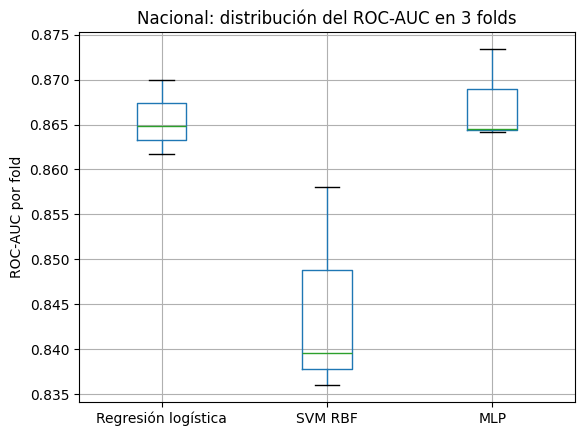

In [123]:
pd.DataFrame(scores_nac).boxplot()
plt.ylabel("ROC-AUC por fold")
plt.title(f"Nacional: distribución del ROC-AUC en {K_FINAL} folds")
plt.show()

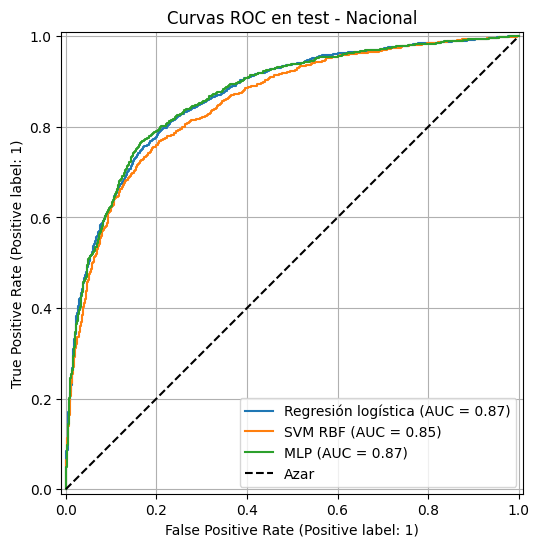

===== Regresión logística =====
              precision    recall  f1-score   support

      Formal       0.78      0.78      0.78      1442
    Informal       0.80      0.80      0.80      1558

    accuracy                           0.79      3000
   macro avg       0.79      0.79      0.79      3000
weighted avg       0.79      0.79      0.79      3000

===== SVM RBF =====
              precision    recall  f1-score   support

      Formal       0.75      0.80      0.78      1442
    Informal       0.80      0.76      0.78      1558

    accuracy                           0.78      3000
   macro avg       0.78      0.78      0.78      3000
weighted avg       0.78      0.78      0.78      3000

===== MLP =====
              precision    recall  f1-score   support

      Formal       0.80      0.76      0.78      1442
    Informal       0.79      0.82      0.80      1558

    accuracy                           0.79      3000
   macro avg       0.79      0.79      0.79      3000
weight

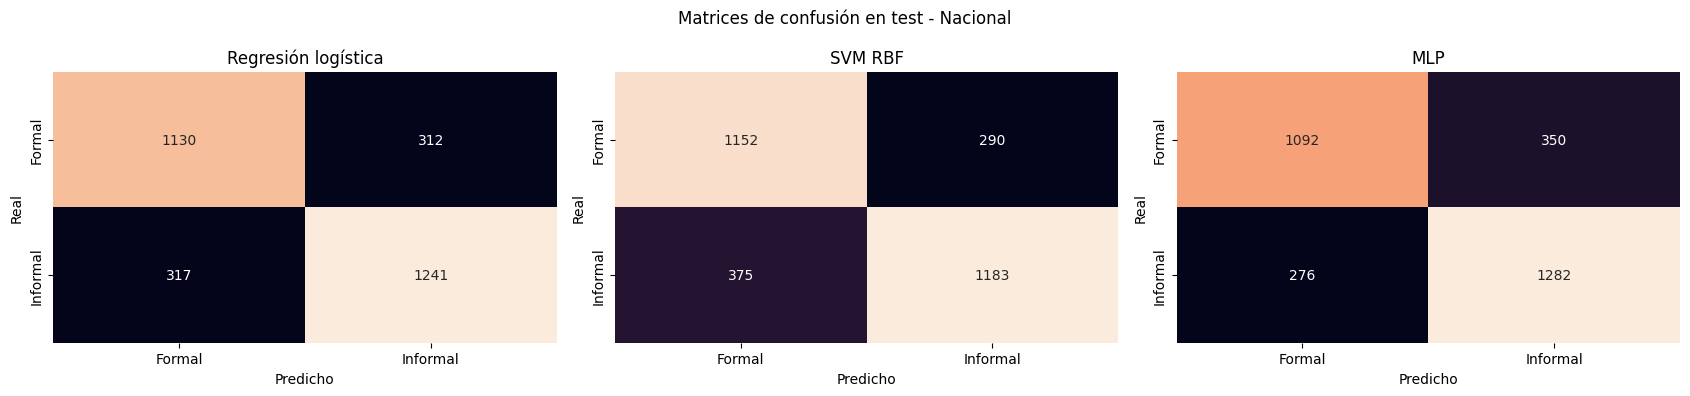

,Modelo,ROC-AUC,Accuracy,Precision,Recall,Specificity,F1
2,MLP,0.8688,0.7913,0.7855,0.8228,0.7573,0.8038
0,Regresión logística,0.8676,0.7903,0.7991,0.7965,0.7836,0.7978
1,SVM RBF,0.8542,0.7783,0.8031,0.7593,0.7989,0.7806


In [124]:
test_nac = evaluar_test(modelos_nac, X_test_nac, y_test_nac, "Nacional")
test_nac.round(4)

### 6.4 Comparación entre conjuntos de datos

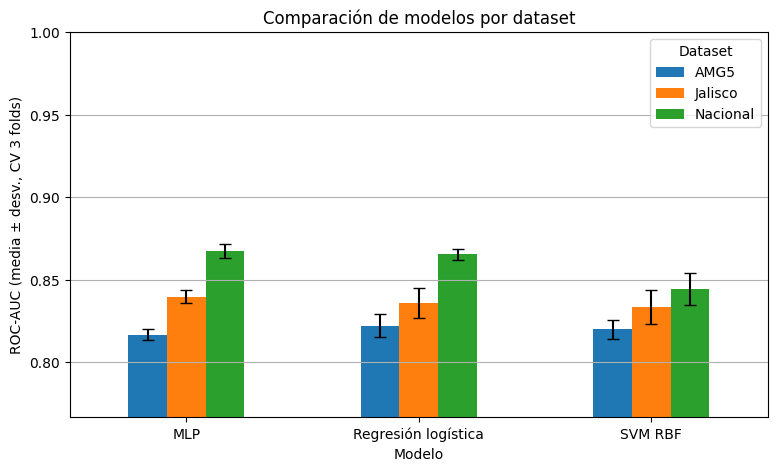

AUC media (CV) por modelo y dataset:
Dataset                AMG5  Jalisco  Nacional
Modelo                                        
MLP                  0.8166   0.8397    0.8674
Regresión logística  0.8222   0.8358    0.8655
SVM RBF              0.8198   0.8334    0.8445

AUC desviación estándar (CV):
Dataset                AMG5  Jalisco  Nacional
Modelo                                        
MLP                  0.0034   0.0039    0.0043
Regresión logística  0.0072   0.0092    0.0034
SVM RBF              0.0060   0.0103    0.0097


In [125]:
tabla_amg["Dataset"] = "AMG5"
tabla_jal["Dataset"] = "Jalisco"
tabla_nac["Dataset"] = "Nacional"
comparacion = pd.concat([tabla_amg, tabla_jal, tabla_nac], ignore_index=True)

pivote_media = comparacion.pivot(index="Modelo", columns="Dataset", values="AUC media")
pivote_std = comparacion.pivot(index="Modelo", columns="Dataset", values="AUC std")

pivote_media.plot.bar(yerr=pivote_std, capsize=4, rot=0, figsize=(9, 5))
plt.ylabel(f"ROC-AUC (media ± desv., CV {K_FINAL} folds)")
plt.ylim(max(0.5, pivote_media.min().min() - 0.05), 1)
plt.title("Comparación de modelos por dataset")
plt.grid(axis="y")
plt.show()

print("AUC media (CV) por modelo y dataset:")
print(pivote_media.round(4))
print("\nAUC desviación estándar (CV):")
print(pivote_std.round(4))

In [126]:
test_amg["Dataset"] = "AMG5"
test_jal["Dataset"] = "Jalisco"
test_nac["Dataset"] = "Nacional"
print("ROC-AUC en el conjunto de prueba:")
pd.concat([test_amg, test_jal, test_nac]).pivot(index="Modelo", columns="Dataset", values="ROC-AUC").round(4)

ROC-AUC en el conjunto de prueba:


Dataset,AMG5,Jalisco,Nacional
Modelo,,,
MLP,0.8178,0.8407,0.8688
Regresión logística,0.8390,0.8409,0.8676
SVM RBF,0.8424,0.8414,0.8542


In [127]:
# Mejores hiperparámetros encontrados por el GP en cada dataset
filas = []
for nombre_df, estudios in [("AMG5", estudios_amg), ("Jalisco", estudios_jal), ("Nacional", estudios_nac)]:
    for nombre, estudio in estudios.items():
        fila = {"Dataset": nombre_df, "Modelo": nombre, "Mejor AUC (CV opt.)": round(estudio["best_value"], 4)}
        fila.update({k: (round(v, 6) if isinstance(v, float) else v) for k, v in estudio["best_params"].items()})
        filas.append(fila)
pd.DataFrame(filas).sort_values(["Modelo", "Dataset"])

,Dataset,Modelo,Mejor AUC (CV opt.),C,l1_ratio,gamma,n_capas,neuronas_1,neuronas_2,alpha,learning_rate_init
2,AMG5,MLP,0.8166,NaN,NaN,NaN,2.0,98.0,53.0,0.000342,0.005290
5,Jalisco,MLP,0.8397,NaN,NaN,NaN,1.0,17.0,54.0,0.000306,0.006225
8,Nacional,MLP,0.8674,NaN,NaN,NaN,2.0,82.0,52.0,0.000630,0.003469
0,AMG5,Regresión logística,0.8222,0.121314,0.297243,NaN,NaN,NaN,NaN,NaN,NaN
3,Jalisco,Regresión logística,0.8358,0.122086,0.242589,NaN,NaN,NaN,NaN,NaN,NaN
6,Nacional,Regresión logística,0.8655,0.121276,0.602688,NaN,NaN,NaN,NaN,NaN,NaN
1,AMG5,SVM RBF,0.8198,3.714712,NaN,0.003063,NaN,NaN,NaN,NaN,NaN
4,Jalisco,SVM RBF,0.8334,3.714712,NaN,0.003063,NaN,NaN,NaN,NaN,NaN
7,Nacional,SVM RBF,0.8445,3.714712,NaN,0.003063,NaN,NaN,NaN,NaN,NaN


In [128]:
pd.DataFrame({"AMG5": tiempos_amg, "Jalisco": tiempos_jal, "Nacional": tiempos_nac}).round(1)

,AMG5,Jalisco,Nacional
Regresión logística,0.0,0.0,0
SVM RBF,0.1,0.4,0
MLP,0.1,0.2,0


## 7. Conclusiones



En base a nuestra hipótesis paraece que los 3 modelos distinguieron de buena manera entre empleo formal e informal en los 3 datasets con valores de ROC-AUC entre 0.8166 y 0.8674. El mejor modelo cambia según el conjunto de datos:

| Conjunto | Mejor modelo | AUC de validación |
|---|---|---:|
| AMG5 | Regresión logística | 0.8222 |
| Jalisco | MLP | 0.8397 |
| Nacional | MLP | 0.8674 |

En AMG5, la regresión logística obtiene el AUC más alto, seguida de cerca por la SVM (0.8198) y el MLP (0.8166). Las diferencias son pequeñas. En Jalisco, el MLP alcanza 0.8397, ligeramente por encima de la regresión logística (0.8358) y la SVM (0.8334). A nivel nacional, el MLP también ocupa el primer lugar (0.8674), pero la regresión logística queda muy cerca (0.8655); la SVM obtiene 0.8445.

Los tres modelos presentan un AUC mayor en el conjunto nacional que en Jalisco y AMG5. Esto indica que, en estas evaluaciones, les resultó más fácil distinguir entre ambas clases a nivel nacional. Asi mismo es de menciionar que el MLP y la regresión logística parecen estar muy parecidos. 

Sobre los hiperparámetros, el MLP seleccionado usa dos capas en AMG5 y nacional, y una en Jalisco, dado a esto podemos concluir que los modelos logran usar datos sociales y demográficos para distinguir si una persona tiene empleo formal e informal lo que nos dice que hay características en las personas que permiten esto por lo tanto hay estrategias que pueden funcionar.


## 8. Referencias

- Abe, S. (2010). *Support vector machines for pattern classification* (2nd ed.). Springer-Verlag London. https://doi.org/10.1007/978-1-84996-098-4
- Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. En *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (pp. 2623–2631). https://doi.org/10.1145/3292500.3330701
- Bradley, A. P. (1997). The use of the area under the ROC curve in the evaluation of machine learning algorithms. *Pattern Recognition, 30*(7), 1145–1159. https://doi.org/10.1016/S0031-3203(96)00142-2
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://doi.org/10.1007/BF00994018
- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press.
- Instituto Nacional de Estadística y Geografía. (2014). *La informalidad laboral. Encuesta Nacional de Ocupación y Empleo: Marco conceptual y metodológico*. INEGI.
- Instituto Nacional de Estadística y Geografía. (2026). *Encuesta Nacional de Ocupación y Empleo (ENOE), población de 15 años y más de edad: Microdatos, segundo trimestre de 2026* [Conjunto de datos]. INEGI. https://www.inegi.org.mx/programas/enoe/15ymas/
- Instituto Nacional de Estadística y Geografía. (s. f.). *Encuesta Nacional de Ocupación y Empleo: Descriptor de archivos y diccionario de datos*. INEGI.
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning with applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. En *3rd International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1412.6980
- Organización Internacional del Trabajo. (2013). *La medición de la informalidad: Manual estadístico sobre el sector informal y el empleo informal*. OIT.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian processes for machine learning*. MIT Press.
- Snoek, J., Larochelle, H., & Adams, R. P. (2012). Practical Bayesian optimization of machine learning algorithms. En *Advances in Neural Information Processing Systems 25* (pp. 2951–2959).
- Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B (Statistical Methodology), 67*(2), 301–320. https://doi.org/10.1111/j.1467-9868.2005.00503.x